# Titanic

El hundimiento del Titanic es uno de los naufragios más infames de la historia.

El 15 de abril de 1912, durante su viaje inaugural, el RMS Titanic, considerado insumergible, se hundió tras colisionar con un iceberg. Desafortunadamente, no había suficientes botes salvavidas para todos a bordo, lo que provocó la muerte de 1502 de los 2224 pasajeros y tripulantes.

Si bien la suerte influyó en la supervivencia, parece que algunos grupos de personas tuvieron más probabilidades de sobrevivir que otros.

En este desafío, te pedimos que construyas un modelo predictivo que responda a la pregunta: "¿Qué tipo de personas tenían más probabilidades de sobrevivir?" utilizando datos de los pasajeros (es decir, nombre, edad, sexo, clase socioeconómica, etc.).

### Objetivo

Tu tarea es predecir si un pasajero sobrevivió al hundimiento del Titanic.

Para cada elemento del conjunto de prueba, debes predecir un valor de 0 o 1 para la variable.

### Variables del dataset Titanic (Kaggle)

- **PassengerId** → Identificador único de cada pasajero.  
- **Survived** → Variable objetivo (`0 = no sobrevivió`, `1 = sobrevivió`).  
- **Pclass** → Clase del boleto (`1 = primera`, `2 = segunda`, `3 = tercera`).  
- **Name** → Nombre completo del pasajero.  
- **Sex** → Sexo del pasajero (`male`, `female`).  
- **Age** → Edad en años (numérica, contiene valores faltantes).  
- **SibSp** → Número de hermanos/esposos/as a bordo.  
- **Parch** → Número de padres/hijos a bordo.  
- **Ticket** → Número del boleto.  
- **Fare** → Tarifa pagada por el pasaje.  
- **Cabin** → Número de cabina (muchos valores faltantes).  
- **Embarked** → Puerto de embarque (`C = Cherbourg`, `Q = Queenstown`, `S = Southampton`).  

### Métrica

Tu puntuación es el porcentaje de pasajeros que predices correctamente. Esto se conoce como exactitud.

### Importación de datos

In [2]:
import numpy as pd

In [4]:
import pandas as pd

In [6]:
data = pd.read_csv("data/train.csv")
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## Exploración de datos

In [9]:
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
data[["Age", "Fare"]].describe()

,Age,Fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

Categorias

In [18]:
def GraficoCategorias(variable_cat, palette, data, proporcion = (18, 8)):
    sns.set_theme(style="whitegrid", context="talk") 
    plt.figure(figsize=proporcion)
    
    total = len(data) 
    
    ax = sns.countplot(
        data=data,
        x=variable_cat,
        hue=variable_cat,              
        order=data[variable_cat].value_counts().index,
        palette= palette, #"deep",
        legend=False                   
    )
    
    # ── Añadimos etiquetas sobre cada barra
    for p in ax.patches:
        # Altura = conteo
        count = int(p.get_height())
        percent = count / total * 100
        texto = f"{count}\n({percent:.1f}%)"
        
        # Coordenadas:
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.text(x, y + 0.02 * total, texto, ha="center", va="bottom", fontsize=12)
    
    # Rango del eje Y ---------------------------------------------------
    lim_sup = data[variable_cat].value_counts().max() * 1.15   # 15 % de aire arriba
    ax.set_ylim(0, lim_sup) 
    
    ax.set_facecolor("#ecf0f1") 
    ax.set_title(f"Distribución de {variable_cat}")
    ax.set_xlabel(variable_cat.capitalize())
    ax.set_ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

**Categoría de clasificación**

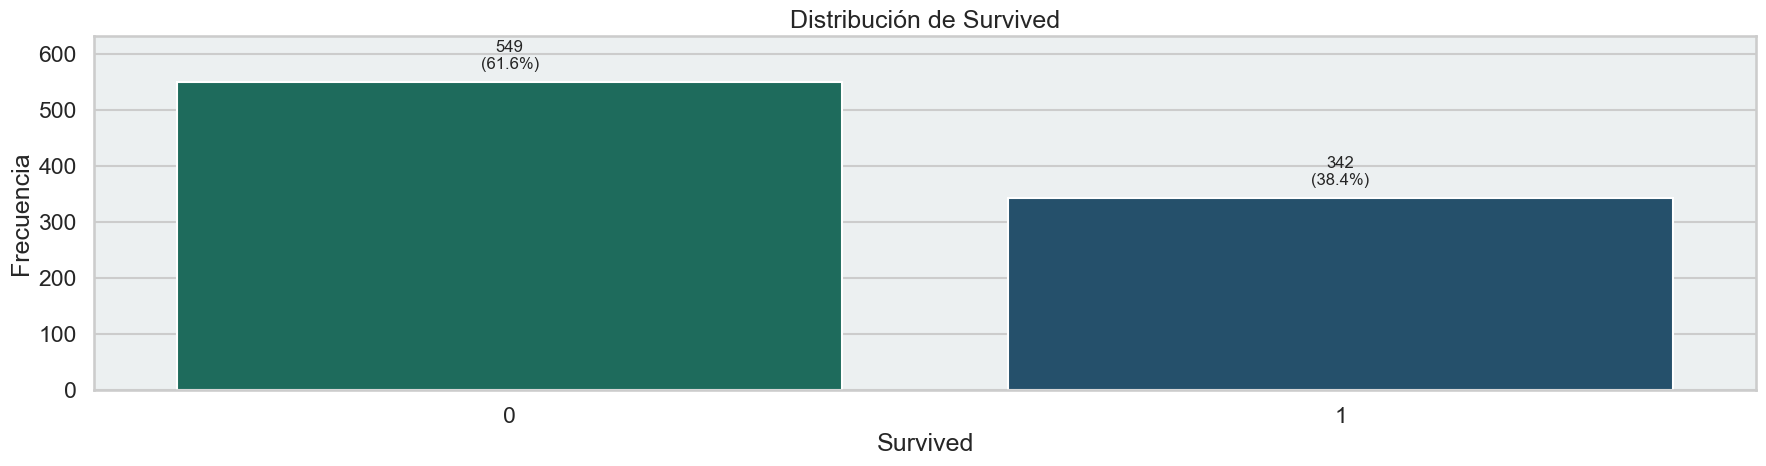

In [21]:
GraficoCategorias("Survived", {0: "#117864", 1: "#1a5276"}, data, proporcion = (18, 5))

En general, observamos que el $38.4\%$ de todas las observaciones son de la etiqueta de nuestro interés, es decir, de personas que sobrevivieron al escenario del accidente del titanic. Esto nos muestra un panorama alentador, si bien no los datos no están equilibrados, esta proporción no es tan alarmante, lo cual nos da una idea de los métodos que podemos usar para abordar este problema de clasificación

**Nivel o clase del pasajero**

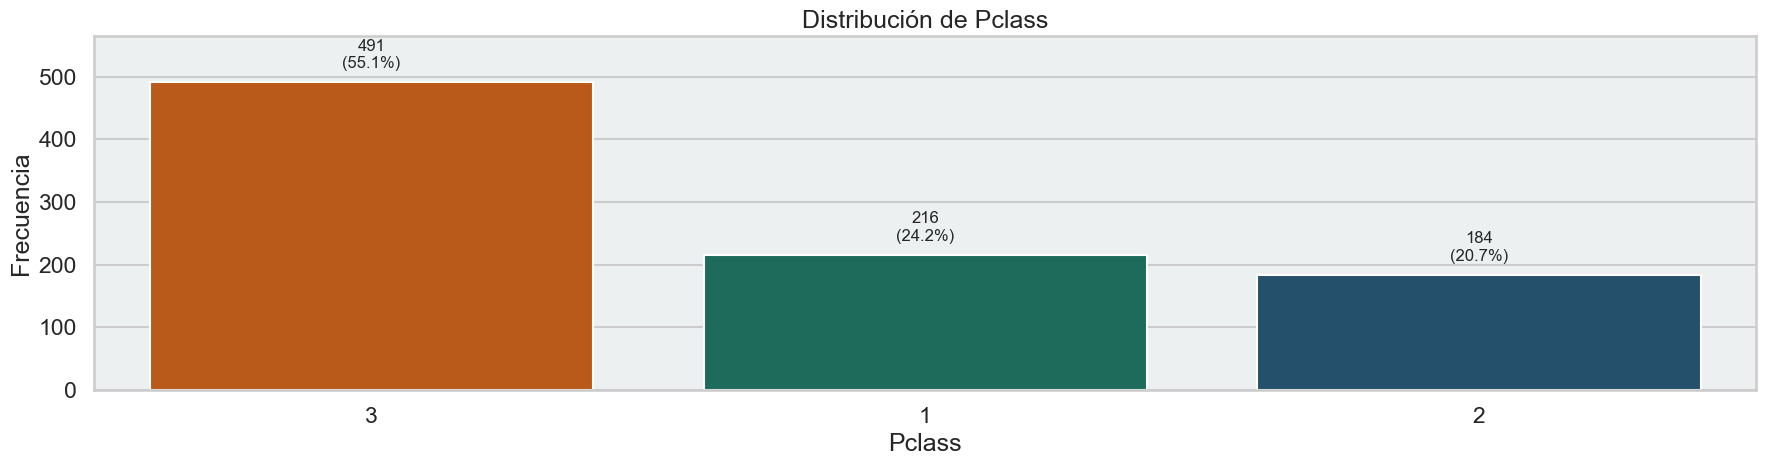

In [25]:
GraficoCategorias("Pclass", {1: "#117864", 2: "#1a5276", 3: "#d35400"}, data, proporcion = (18, 5))

Observamos que en más del $55\%$ de los pasajeros pertencen a la tercera clase, lo cual es algo esperado ya que es una categoría más popular y de menor precio, la cual, una mayor cantidad de personas han podido costear. Le sigue los pasajeros de primera clase llegando a un $24.2\%$, siendo estos los pasajeros VIP, lo cual sorprende, porque están por encimas de las segunda clase, llegando estos a ser el $20.7\%$ del total de pasajeros.

**_Sobrevivientes por clase_**

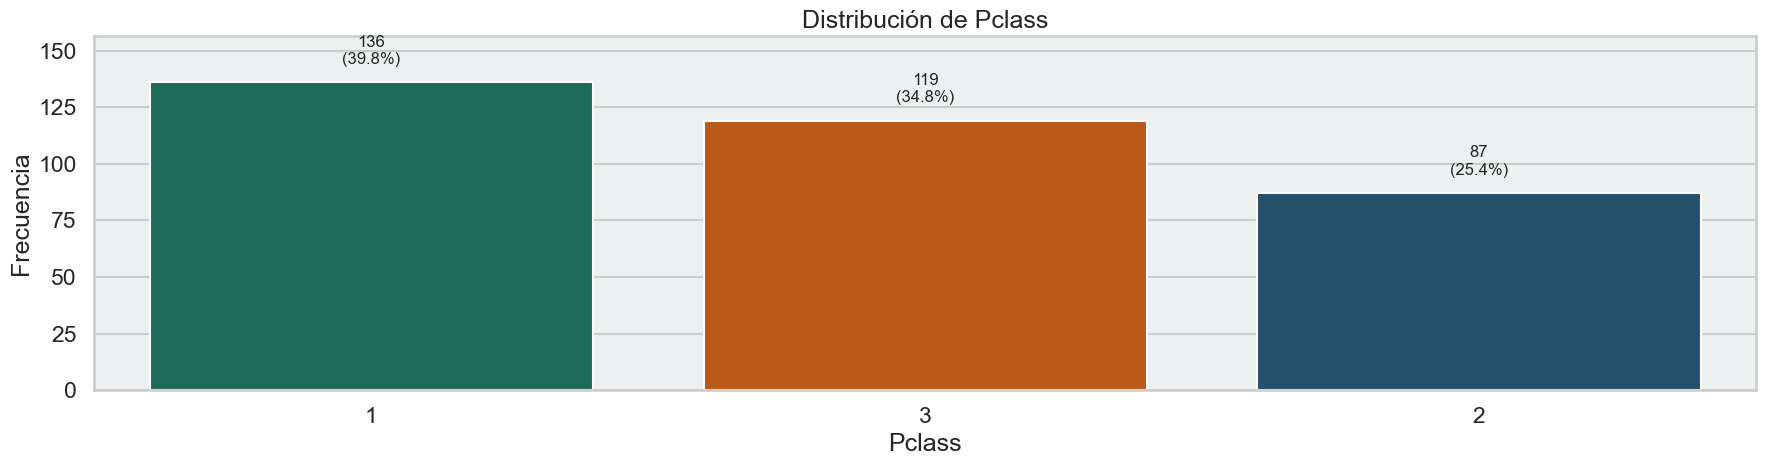

In [29]:
GraficoCategorias("Pclass", {1: "#117864", 2: "#1a5276", 3: "#d35400"}, data[data["Survived"] == 1], proporcion = (18, 5))

En el panorama de los sobrevivientes, observamos que casi el $40\%$ de los sobrevivientes fueron de primera clase, lo que nos da indicios en pensar que estos pasajeros tuvieron ciertas ventajas o privilegios en comparación a los demás, si bien no está muy alejado a los pasajeros de tercera clase, llegando a casi un $35\%$, es decir, con una leve diferencia de 17 personas aproximadamente. Lo que podría causar curiosidad es por qué los pasajeros de la segunda clase tienen una menor cantidad de los de tercera clase, esto se explica fácilmente, ya que la los pasajeros de tercera clase son los que se encuentrar en mayor cantidad, es decir 491 de los pasajeros son de esta categoria, menos de la tercera parte de estos pasajeros solo sobrevivieron. Por lo tanto, estos resultados ya se esperaban.

In [32]:
136/216, 87/184, 119/491

(0.6296296296296297, 0.47282608695652173, 0.24236252545824846)

**_Fallecidos por clase_**

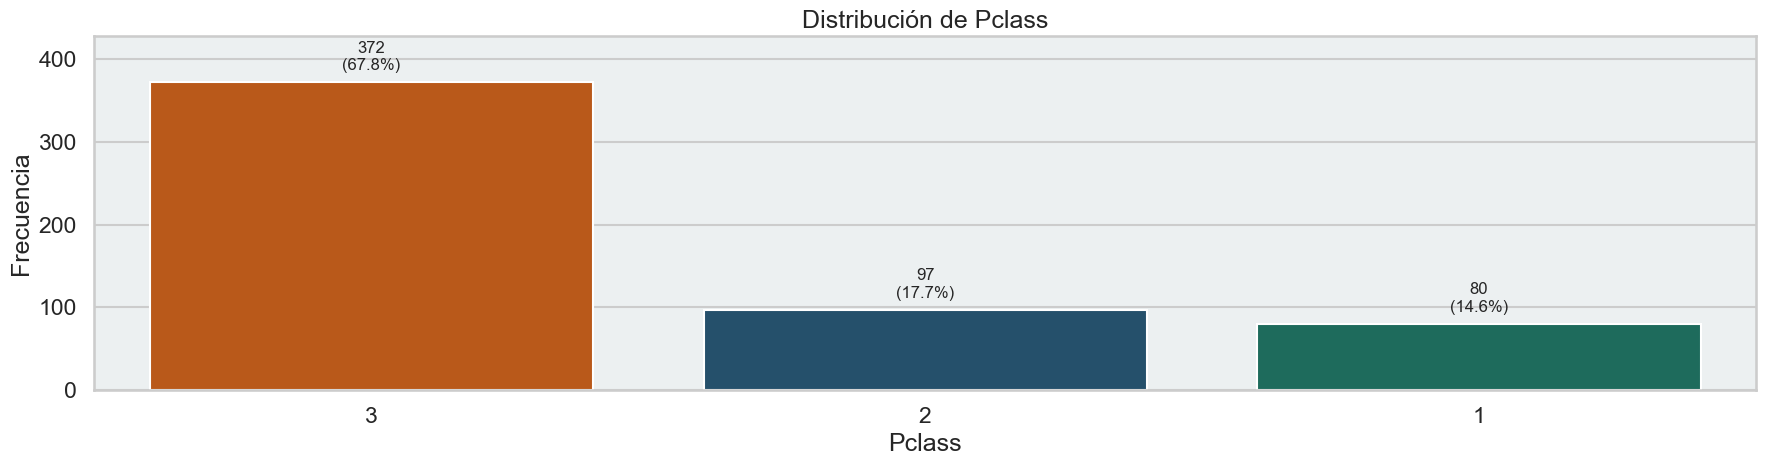

In [35]:
GraficoCategorias("Pclass", {1: "#117864", 2: "#1a5276", 3: "#d35400"}, data[data["Survived"] == 0], proporcion = (18, 5))

Como es de esperar, la gran cantidad de personas fallecidas fueron de la tercera clase, lo que confirma que estos pasajeron no tuvieron lugares, posiciones ni oportunidades provilegiadas a la hora de evacuar. Solo el $14.6\%$ de los fallecidos son de la primera clase, pero esto equivale al $37\%$ aproximadamente del total de pasajeros de esta clase, **lo cual nos dice que el solo hecho de haber estado en una mejor clase, no asegura siempre de que se pueda sobrevivir a esta lamentable hecho**. Las intepretaciones con la segunda clase son similares, solo el $17.7\%$ de los fallecidos son del esta categaría, lo cual nos das, más de la mitad de la segunda clase, que no es un número despreciable de personas.

In [38]:
80/216, 97/184, 372/491

(0.37037037037037035, 0.5271739130434783, 0.7576374745417516)

**Sexo de los pasajeros**

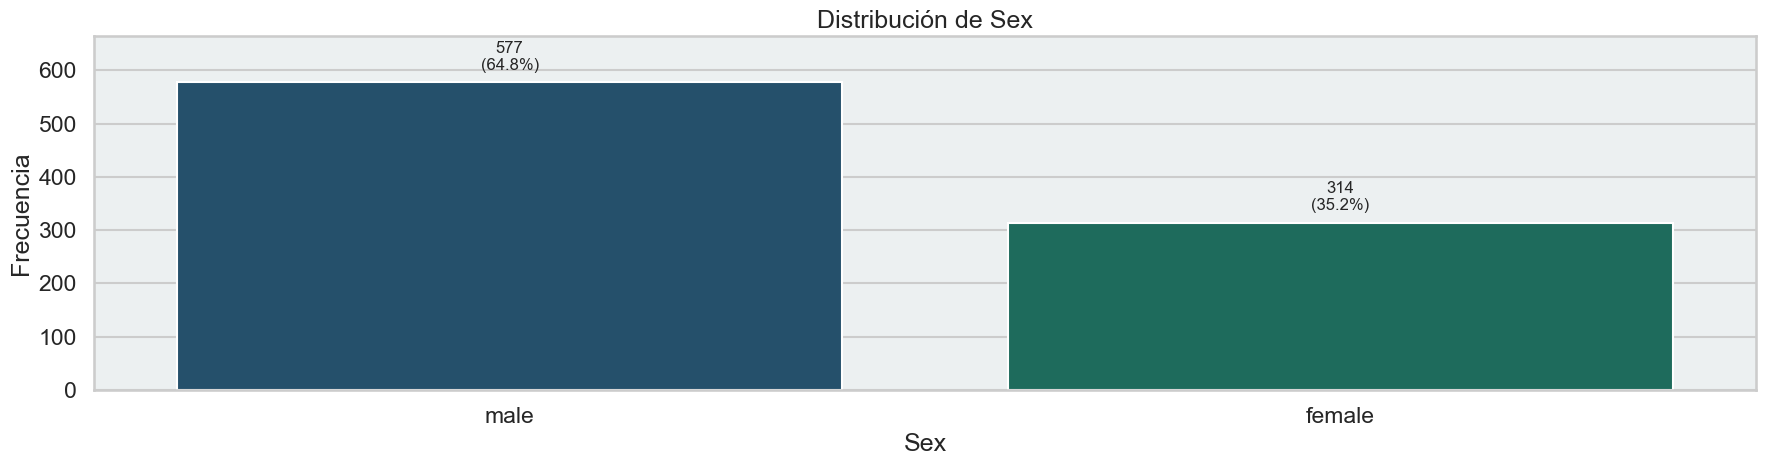

In [41]:
GraficoCategorias("Sex", {'female': "#117864", 'male': "#1a5276"}, data, proporcion = (18, 5))

El $64%\$ del total de pasajeros eran varones, lo cual muestra las oportunidades que tenía este genero en esta etapa de la historia a diferencia de las mujeres, que lo más probale es que sean acompañantes de algún varón.

**Distribución de sobrevivientes por sexo**

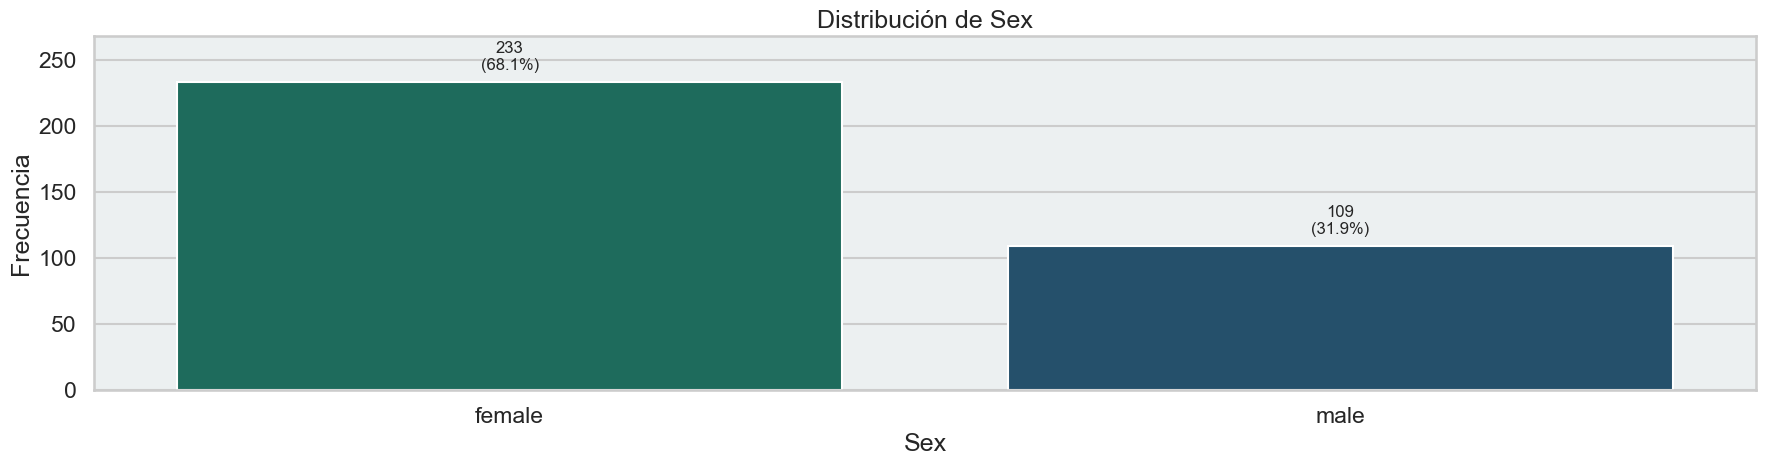

In [45]:
GraficoCategorias("Sex", {'female': "#117864", 'male': "#1a5276"}, data[data["Survived"] == 1], proporcion = (18, 5))

Es claro que la gran mayoría de personas sobrevivientes fueron mujeres, para ser exactos, el $68.1\%$ han sido mujeres, lo que nos dice que más del $74\%$ de mujeres que abordaron en el titanic, fueron sobrevivientes. Esto puede darnos indicios a que ser una mujer en el titanic, nos de más posibilidades de sobrevivir, pero no se garantiza en su totalidad. Por otro lado, el porcentaje de  hombres de los sobrevivientes es casi de $32\%$, lo que nos da menos del $19\%$ de hombres sobrevivientes al total de hombres que abordaron el titanic. Estos resultados puedes ser explicados porque se dio más prioridad de rescate a las mujeres a diferencia que los hombres.

In [48]:
109/577, 233/314

(0.18890814558058924, 0.7420382165605095)

**Distribución de fallecidos por sexo**

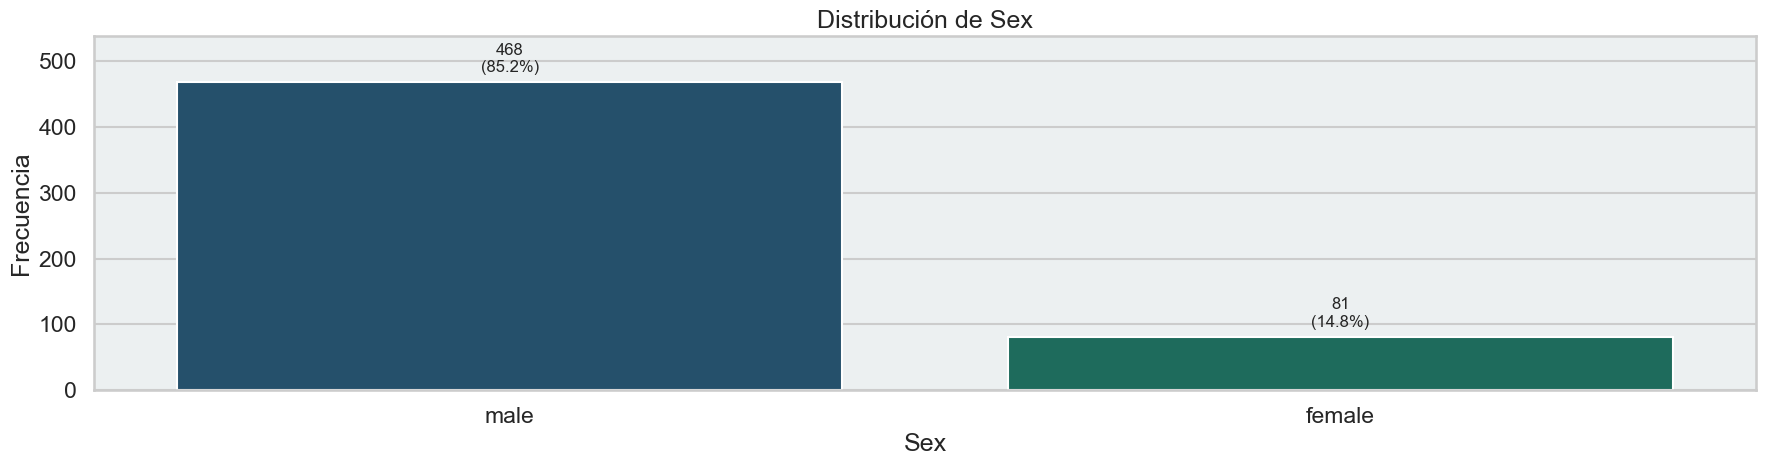

In [51]:
GraficoCategorias("Sex", {'female': "#117864", 'male': "#1a5276"}, data[data["Survived"] == 0], proporcion = (18, 5))

Tal como vimos anteriormente, el gran porcentaje de persona que han fallecido fueron hombres, lo cual muestra grandes indicios de que el sexo en una variable determinante para saeber si un pasajero sobrevive o no.

In [54]:
468/577, 81/314

(0.8110918544194108, 0.25796178343949044)

**Número de hermanos o cónyuge que acompañaban al pasajero en el barco** 

Incluye hermanastros/as y esposos/as; no incluye prometidas/os o amantes.


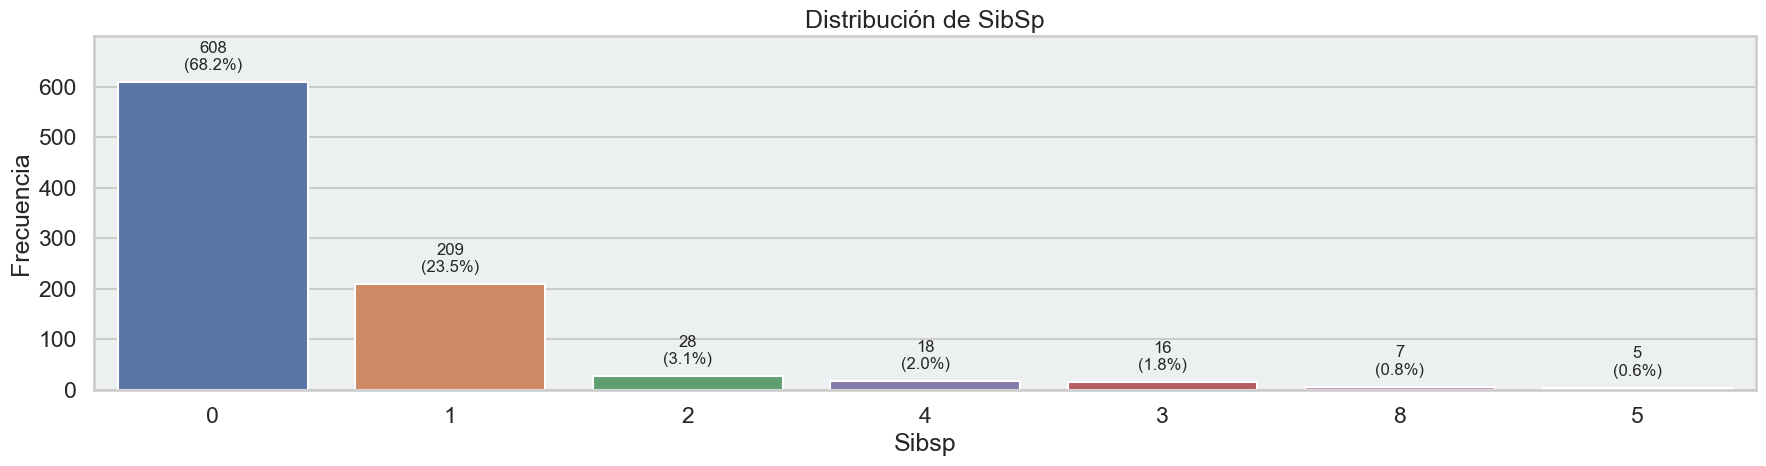

In [57]:
GraficoCategorias("SibSp", "deep" , data, proporcion = (18, 5))

Este gráfico nos indica que la gran mayoría de pasajeros subieron al titanic sin hermanos o esposos, es probable que sean personas solteras con la intención de pasar un tiempo solo. Vemos también que hay un $23.5\%$ de personas que han ido en pareja, ya seas con sus esposos o hermanos. Es muy raro ver pasajeros que asistieron con una numerosa cantidad de hermanos o parejas, posiblemente sean familias muy puntuales que han ido a pasar unas vacaciones en el crucero.

**Distribución de Sobreviviente según número de hermanos o cónyuge que acompañaban al pasajero en el barco**

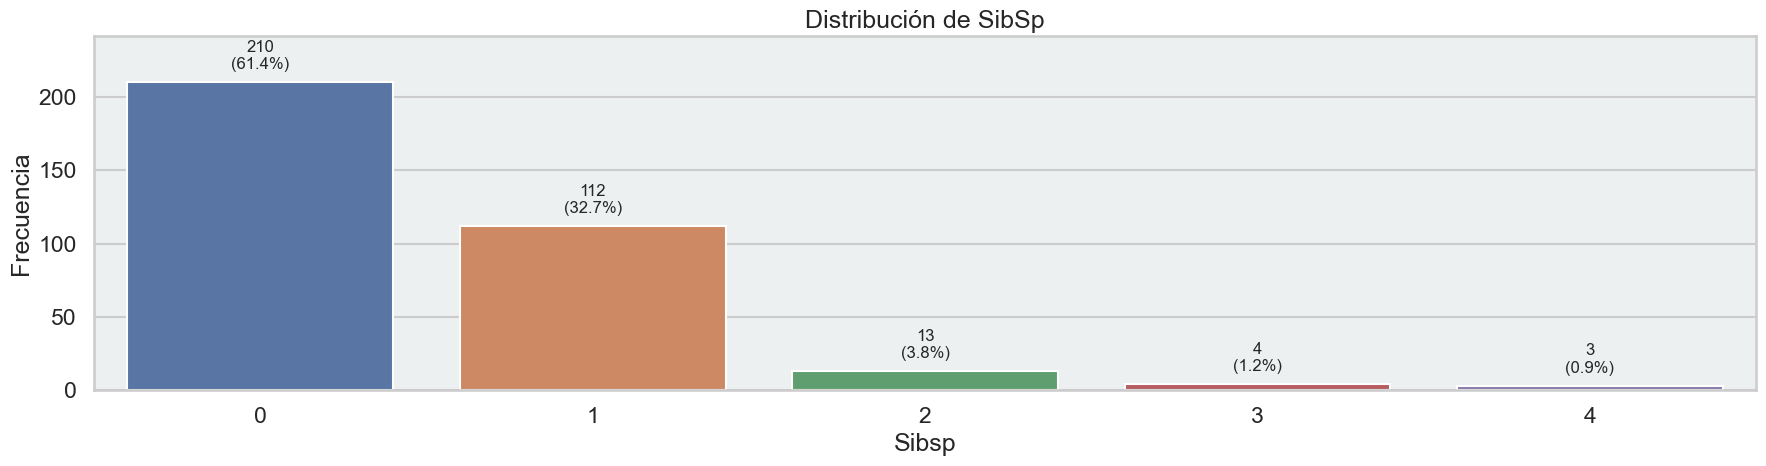

In [61]:
GraficoCategorias("SibSp", "deep" , data[data["Survived"] == 1], proporcion = (18, 5))

**Distribución de Fallecidos según número de hermanos o cónyuge que acompañaban al pasajero en el barco**

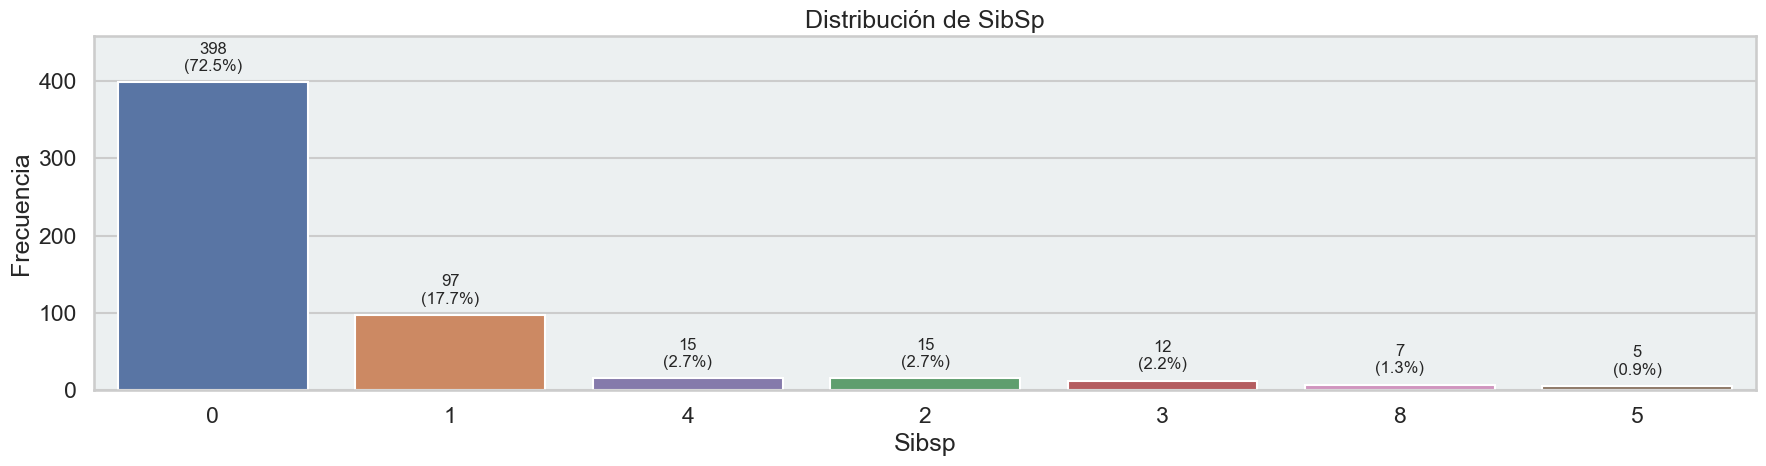

In [64]:
GraficoCategorias("SibSp", "deep" , data[data["Survived"] == 0], proporcion = (18, 5))

No se observa diferencias en la distribución de la cantidad de número de hermanos o cónyuge que acompañaban al pasajero en el barco sea o no si existe sobrevivientes o no. Lo que si se puede afirmar es que todos los pasajeros con más de 4 hermanos o cónyuges, no sobrevivieron.

**Distribución del número de padres o hijos que viajaban en el mismo boleto**

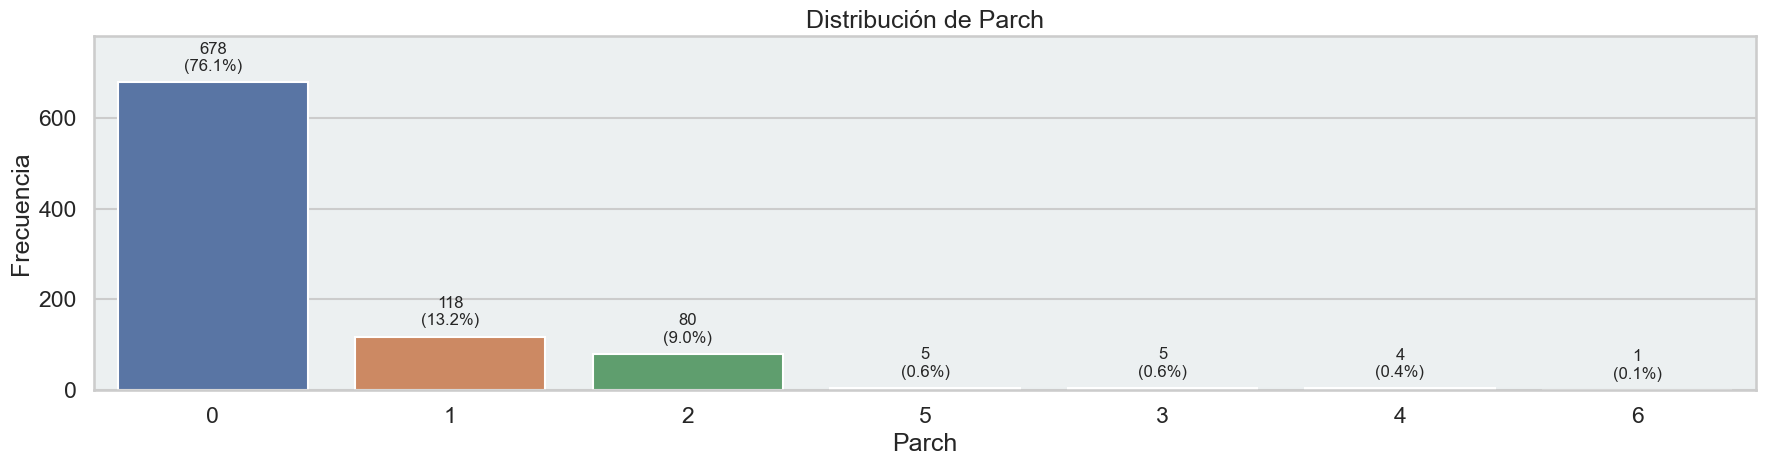

In [68]:
GraficoCategorias("Parch", "deep" , data, proporcion = (18, 5))

Esta distribución concuerda con las hipótesis anteriores, donde la mayoría de pasajeros han ido solos a este viaje. El $13.2\%$ fue con un acompañante (sea padres o hijos). El $9\%$ ffue con dos y el resto de psajeros con más de 2.

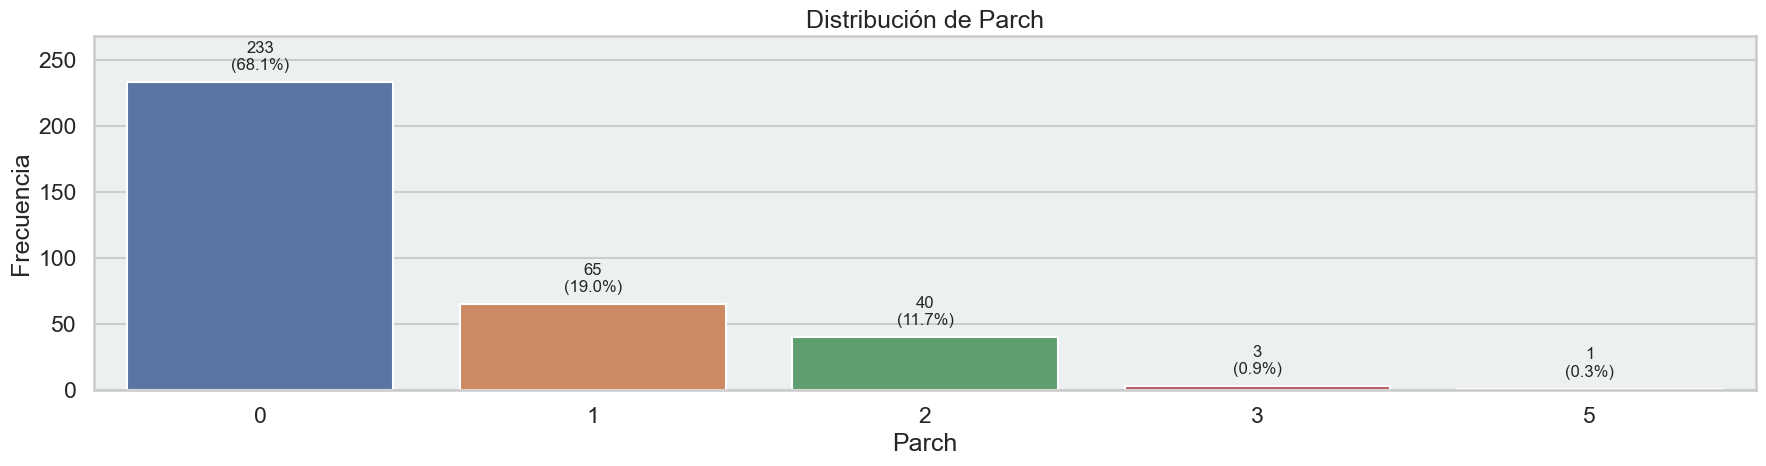

In [71]:
GraficoCategorias("Parch", "deep" , data[data["Survived"] == 1], proporcion = (18, 5))

La distribución de sobrevivientes, casi no cambia, mateniendo la misma proporción, lo cual podría indicar que esta variable no impacta en la variable objetivo.

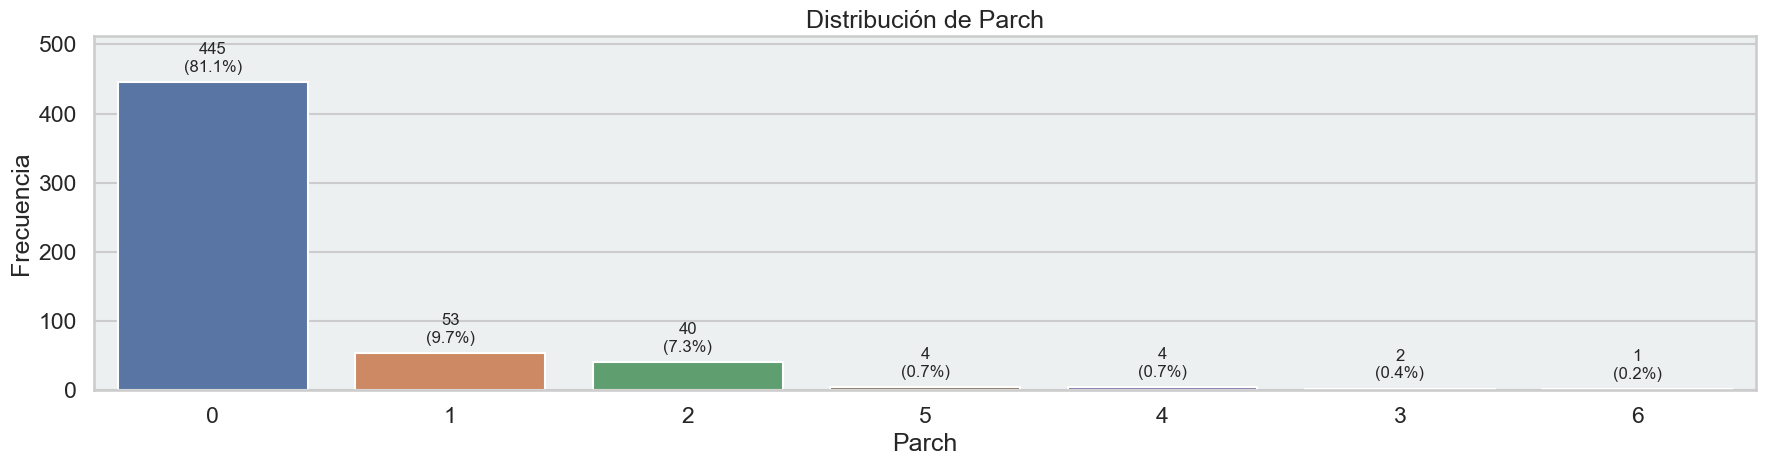

In [74]:
GraficoCategorias("Parch", "deep" , data[data["Survived"] == 0], proporcion = (18, 5))

Si bien la proporción se mantiene, se observa que los pasajeros con 4 y 6 acompañantes (padres o hijos) murieron, lo cual puede ser explicado como la falta de orpotunidad en poder participar del rescate al ser tantos. En general no parecer ser una variable que impacte tanto en decidir si un pasajero sobrevive o no.

**Distribución de Puerta de Embarque en donde ingresaron los pasajeros**

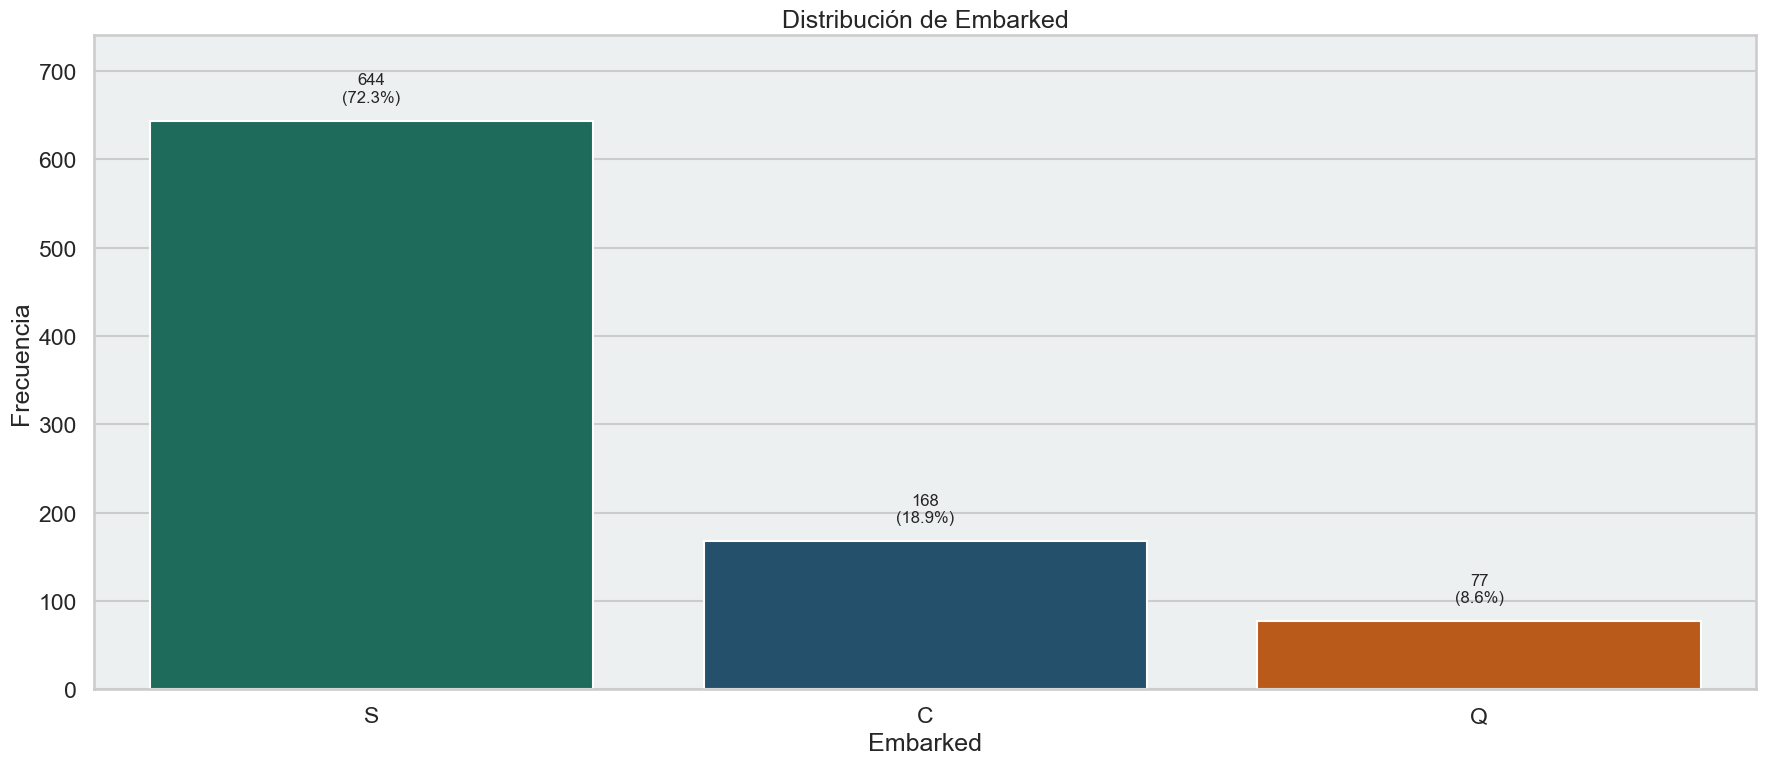

In [82]:
GraficoCategorias("Embarked", {"S": "#117864", "C": "#1a5276", "Q": "#d35400"} , data, proporcion = (18, 8))

Claramente se observa que el embarque por la puerta S fue el más concurrido, llegando al $72.3\%$ de todos los pasajeros. La puerta C, llega al $19.9\%$ y la puerta Q solo llega al $8.6\%$.

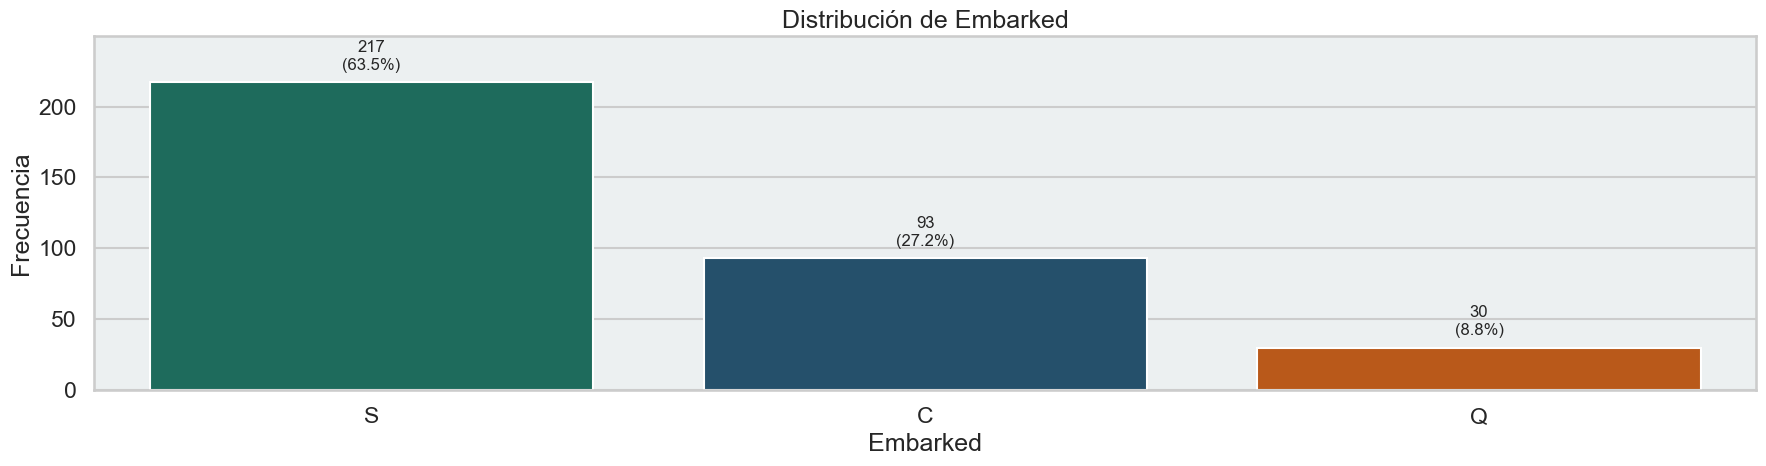

In [63]:
GraficoCategorias("Embarked", {"S": "#117864", "C": "#1a5276", "Q": "#d35400"}, data[data["Survived"] == 1], proporcion = (18, 5))

In [64]:
217/644, 93/168, 30/77

(0.33695652173913043, 0.5535714285714286, 0.38961038961038963)

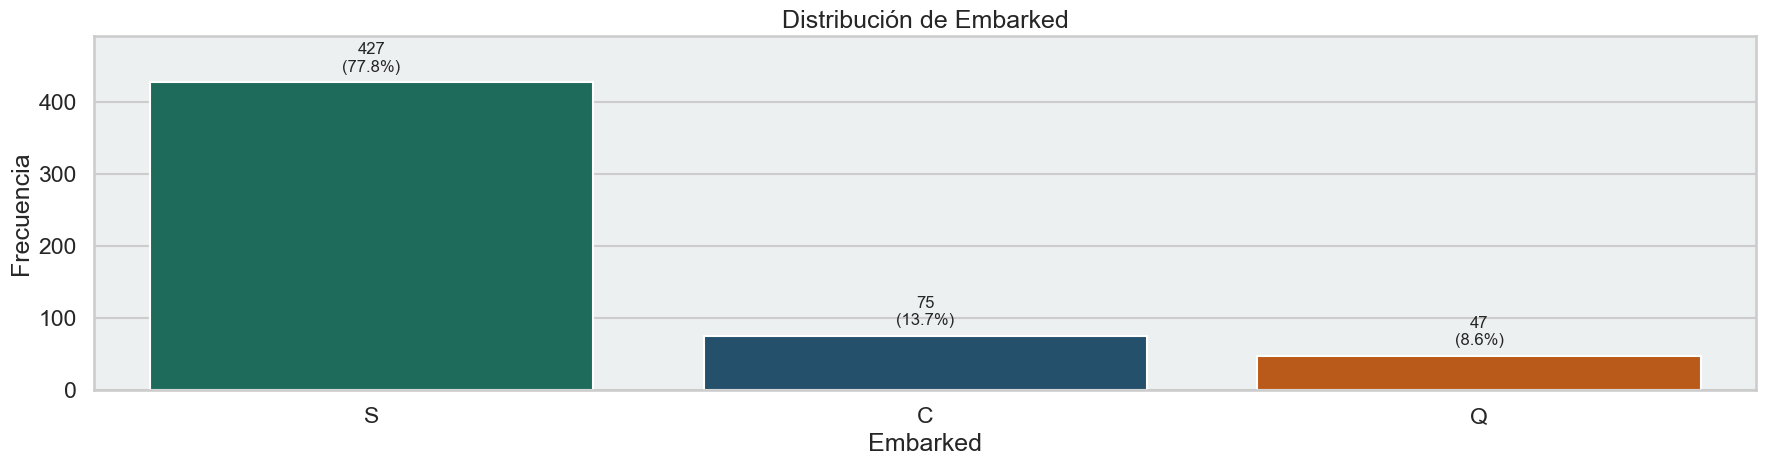

In [65]:
GraficoCategorias("Embarked",  {"S": "#117864", "C": "#1a5276", "Q": "#d35400"}, data[data["Survived"] == 0], proporcion = (18, 5))

No se observan diferencias en las distribuciones de los pasajeros en caso han sobrevivido o no según su puerta de embarque.

In [67]:
def GraficoNumerico(variable_num, data, bins=30, kde=True, color="#3498db", proporcion=(18, 8)):

    sns.set_theme(style="whitegrid", context="talk")
    plt.figure(figsize=proporcion)
    
    total = len(data)
    
    ax = sns.histplot(
        data=data,
        x=variable_num,
        bins=bins,
        kde=kde,
        color=color,
        edgecolor="white"
    )

    for p in ax.patches:
        count = int(p.get_height())
        if count == 0:
            continue
        percent = count / total * 100
        texto = f"{count}\n({percent:.1f}%)"
        
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.text(x, y + total * 0.005, texto, ha="center", va="bottom", fontsize=11)

    max_count = max([p.get_height() for p in ax.patches])
    ax.set_ylim(0, max_count * 1.15)
        
    ax.set_facecolor("#ecf0f1")
    ax.set_title(f"Histograma de {variable_num}")
    ax.set_xlabel(variable_num.capitalize())
    ax.set_ylabel("Frecuencia")
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

In [68]:
def GraficaBoxPlot(data, x, size = (18, 5)):
    plt.figure(figsize = size)
    sns.boxplot(
        data=data, x=x , orient = "h",
        notch=True, showcaps=False,
        flierprops={"marker": "x"},
        boxprops={"facecolor": (.3, .5, .7, .5)},
        medianprops={"color": "r", "linewidth": 2},
    )

def GraficaBoxPlot2(data, x, y, size = (18, 5)):
    plt.figure(figsize = size)
    sns.boxplot(
        data=data, x=x , y = y, orient = "h",
        notch=True, showcaps=False,
        flierprops={"marker": "x"},
        boxprops={"facecolor": (.3, .5, .7, .5)},
        medianprops={"color": "r", "linewidth": 2},
    )

**Distribución de la edad de los pasajeros**

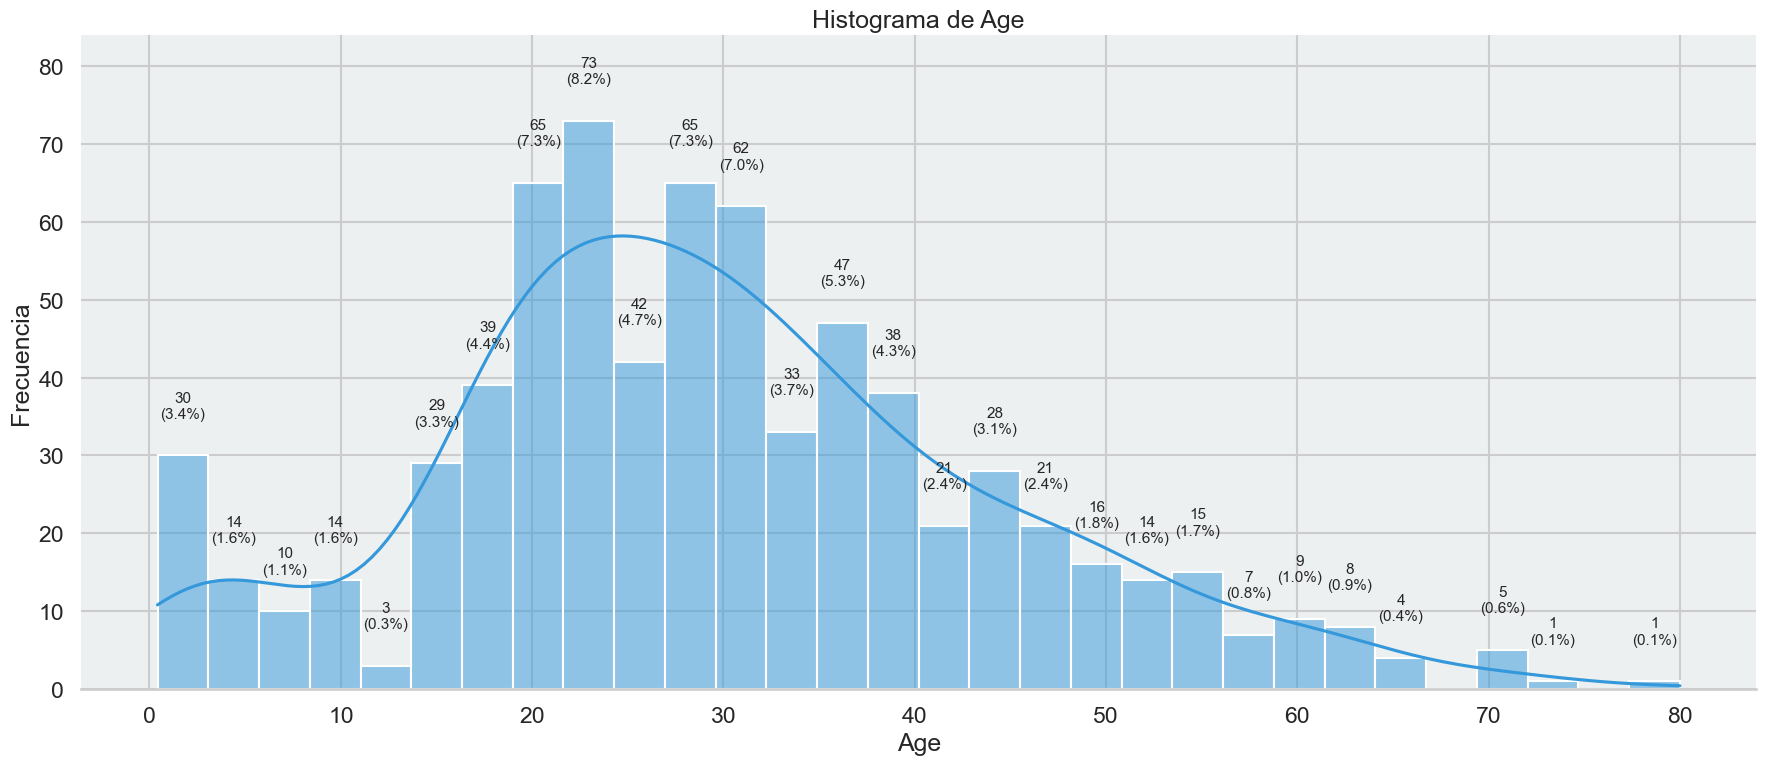

In [70]:
GraficoNumerico("Age", data, bins=30, kde=True, color="#3498db")

En general, observamos una distribución asimétrica a la derecha, con una mayor concentración entre las edades de entre 20 y 30 años.

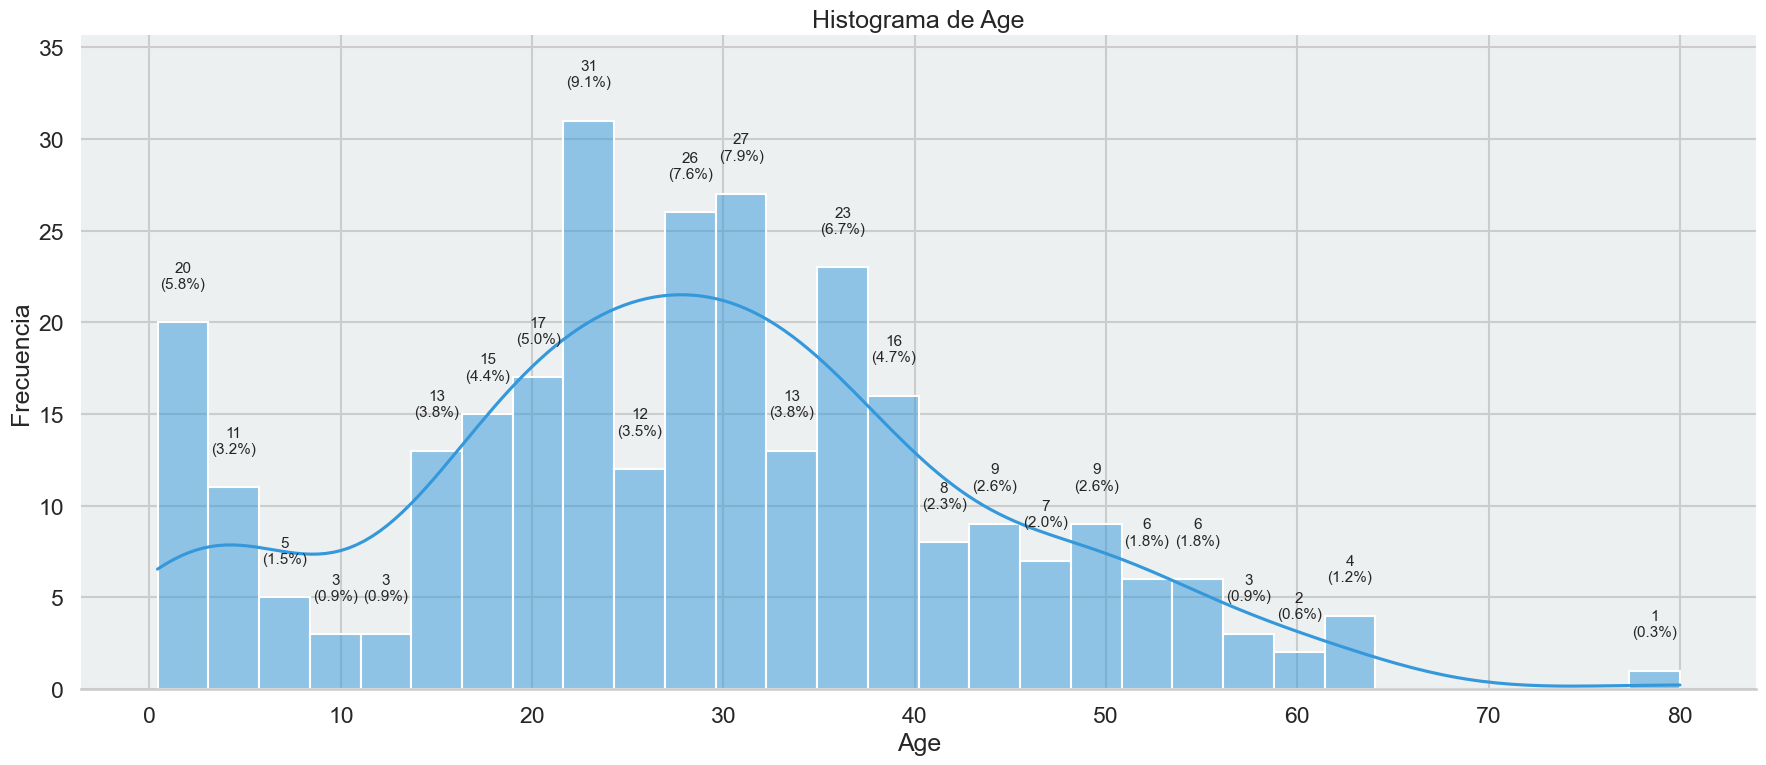

In [72]:
GraficoNumerico("Age", data[data["Survived"] == 1], bins=30, kde=True, color="#3498db")

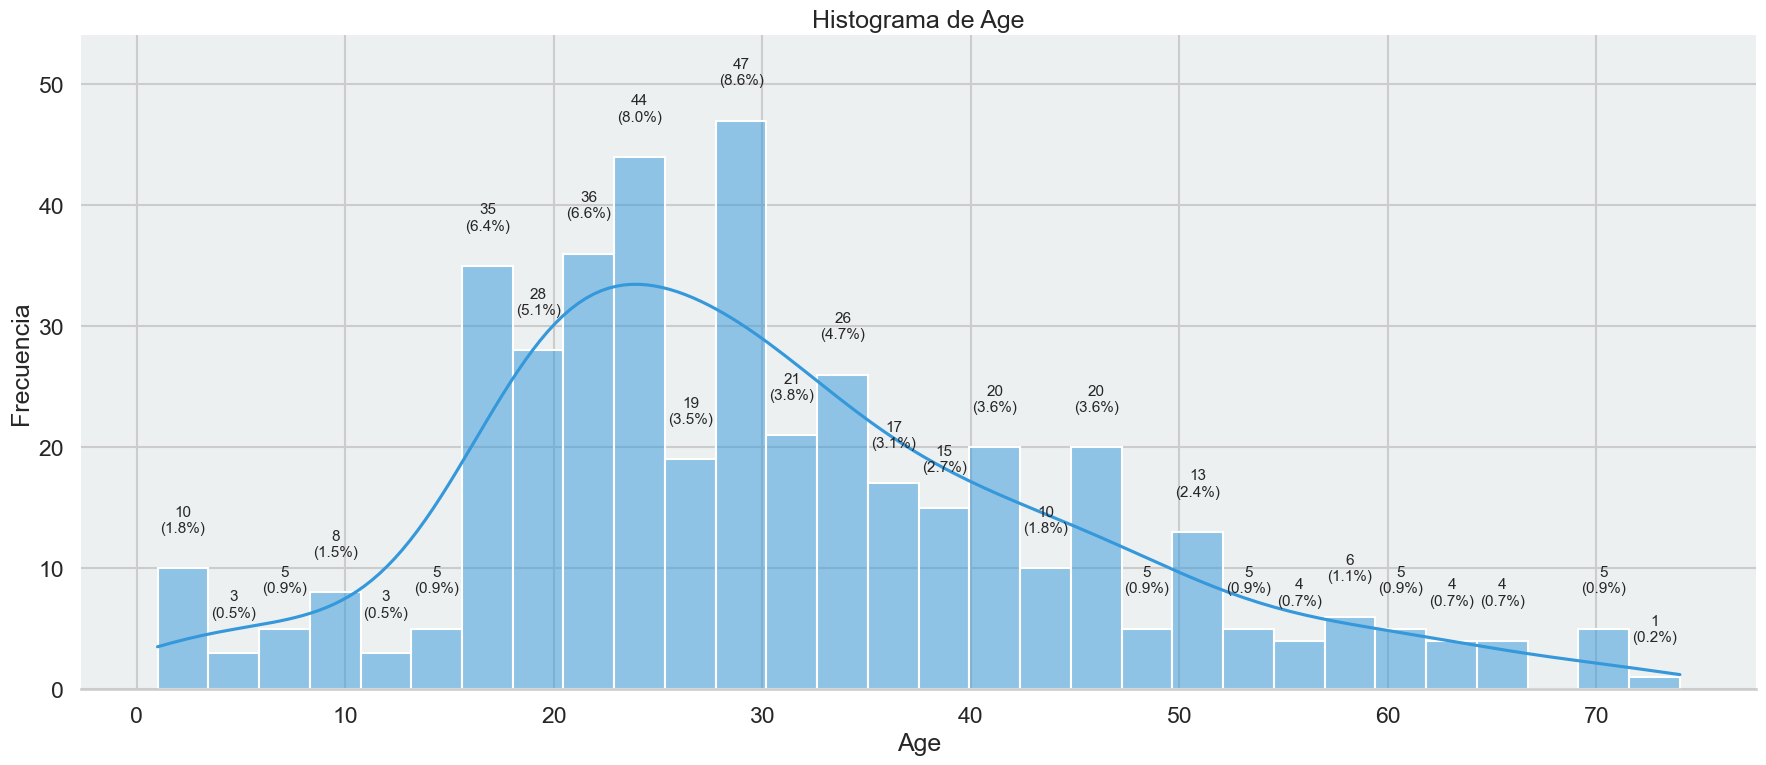

In [73]:
GraficoNumerico("Age", data[data["Survived"] == 0], bins=30, kde=True, color="#3498db")

Si bien hay una ligera diferencia en la distribución de la edad para pasajeros sobrevivientes a la de los que fallecieron, en general no se observan indicios que esta variable sea determinante en nuestra decisión.

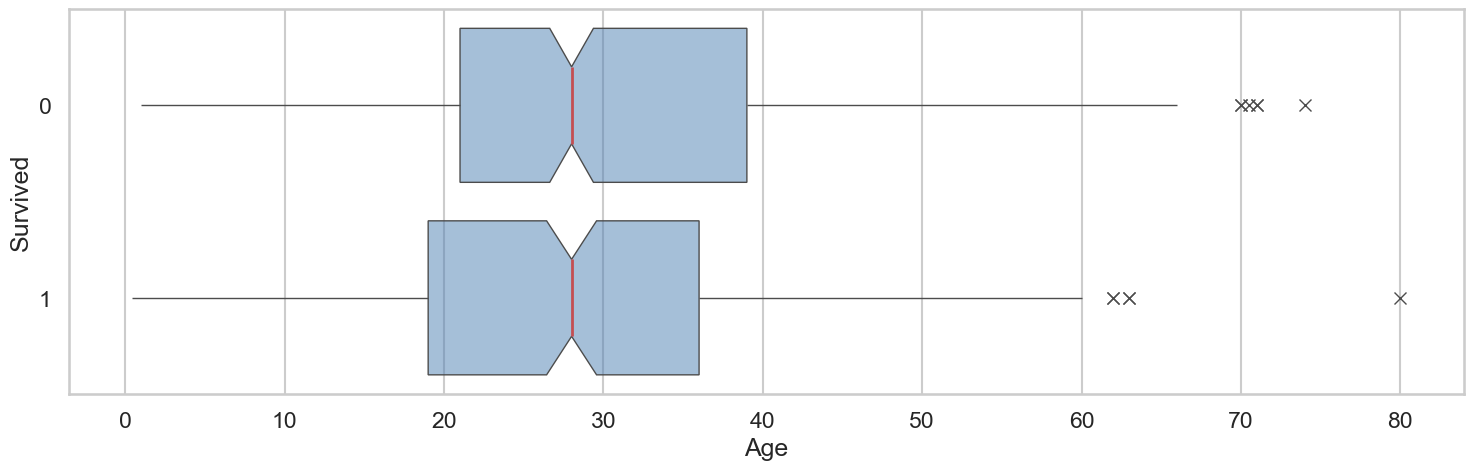

In [75]:
GraficaBoxPlot2(data, x = "Age", y = "Survived")

**Distribución del precio del pasaje**

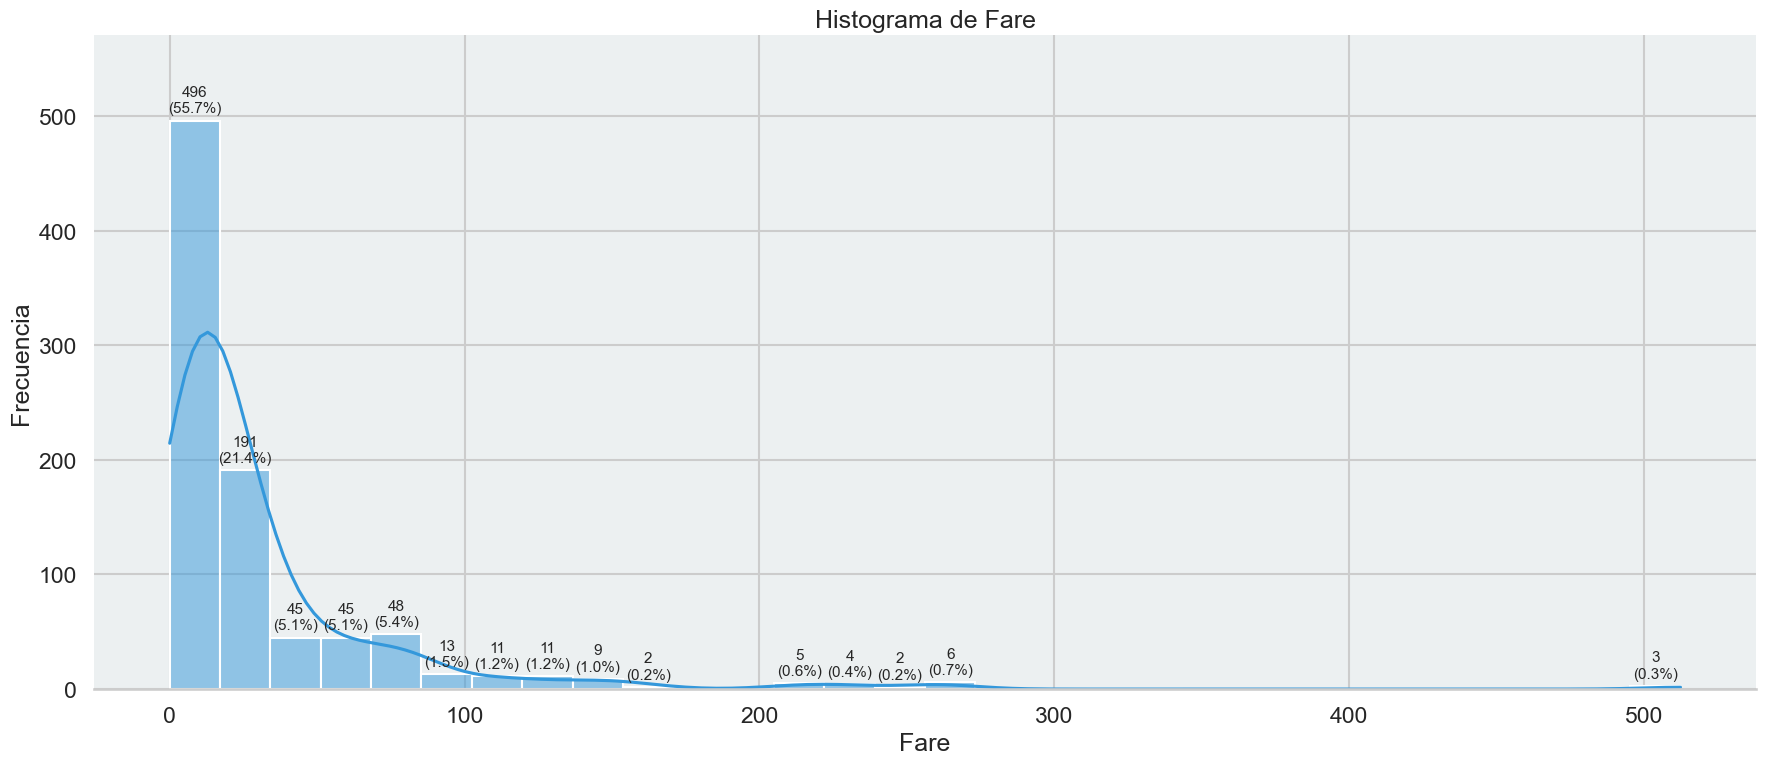

In [77]:
GraficoNumerico("Fare", data, bins=30, kde=True, color="#3498db")

La gran mayoría de pajeros realizó un pago por debajo de los 10 dolares, esto debido a que la más de la mitad de pasajeros están en la tercera clase.

**Ditribución de las precios de los Sobrevivientes**

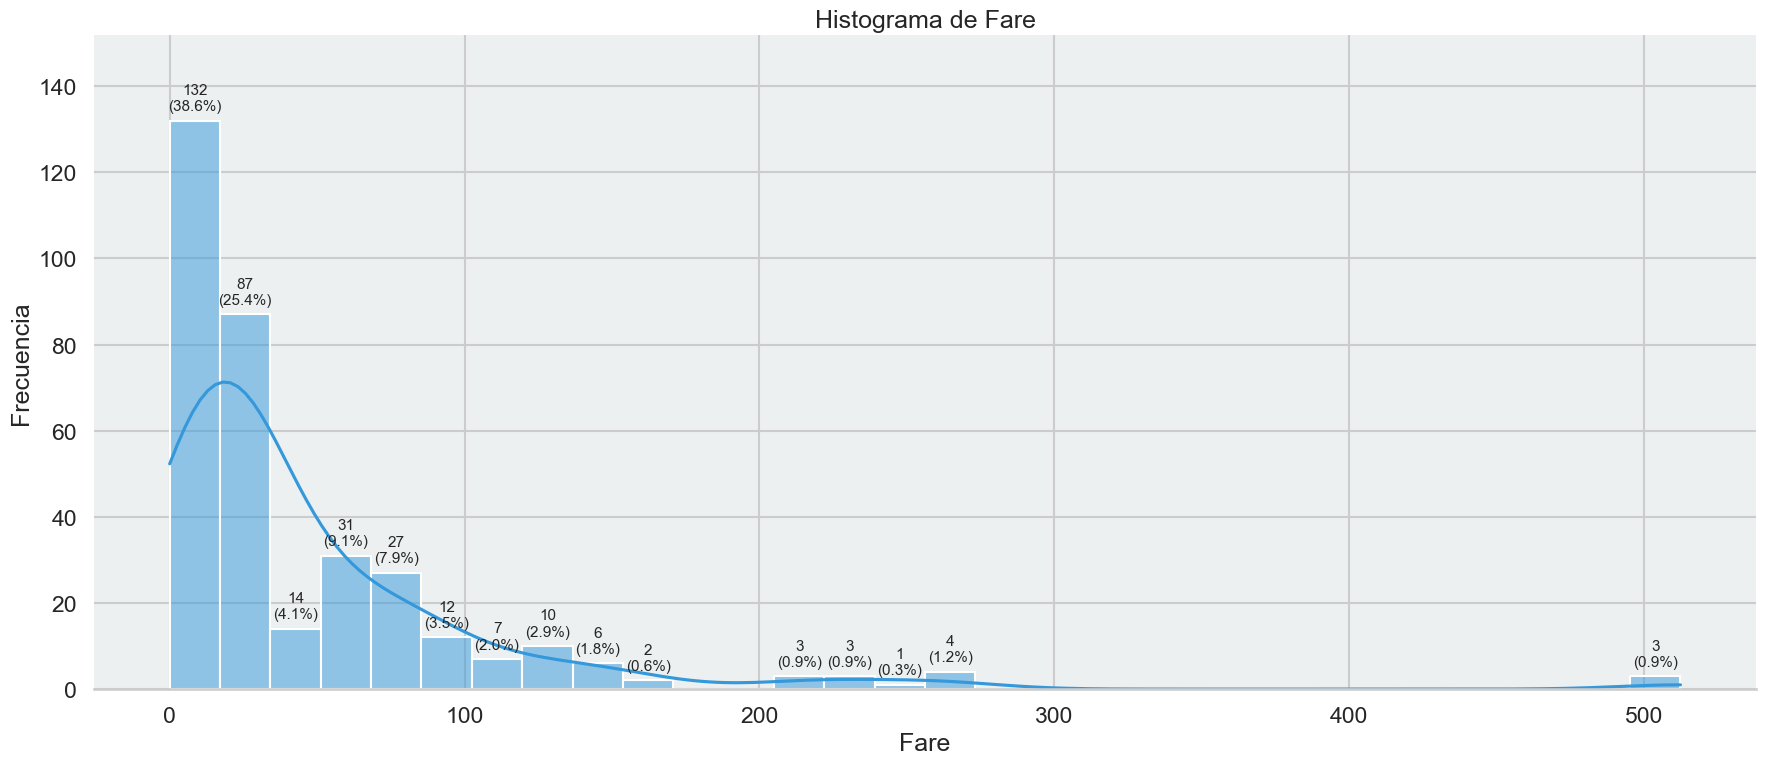

In [80]:
GraficoNumerico("Fare", data[data["Survived"] == 1], bins=30, kde=True, color="#3498db")

**Ditribución de las precios de los fallecidos**

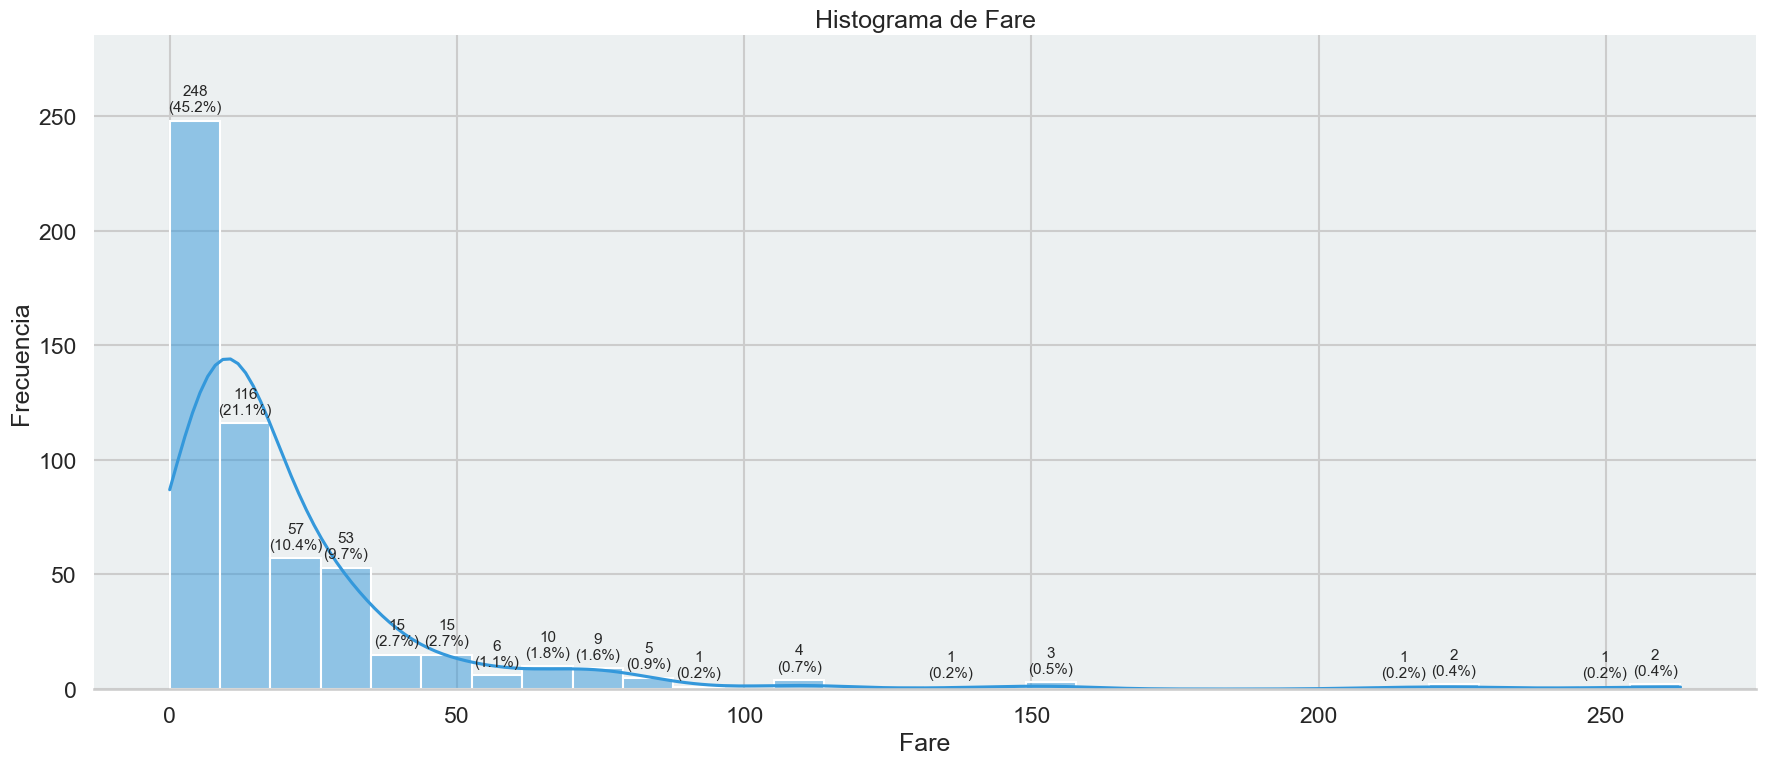

In [82]:
GraficoNumerico("Fare", data[data["Survived"] == 0], bins=30, kde=True, color="#3498db")

Si bien, no existe una diferencia marcada en la distribución de precios, vemos que todas las personas que pagaron más de 250 dolares por el ingreso al titanic, sobrevivieron.

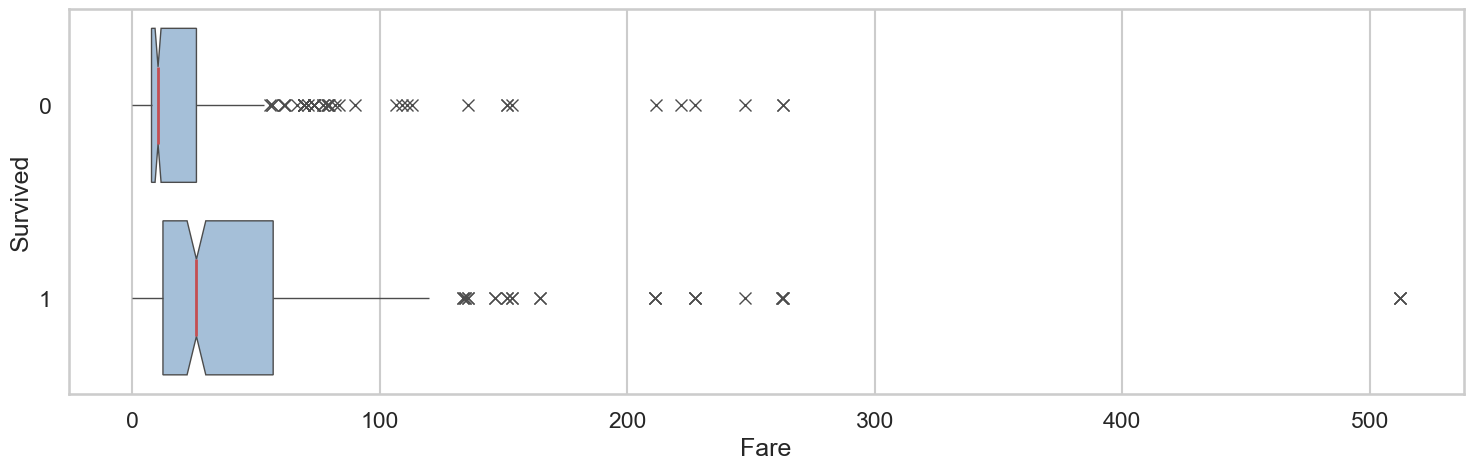

In [84]:
GraficaBoxPlot2(data, x = "Fare", y = "Survived")

# Enunciado: Ticket promedio por canal

Una empresa de retail desea evaluar si existe una diferencia significativa en el **ticket promedio de compra** entre los clientes que compran en el **canal Online** y los que compran en la **Tienda física**.  
La gerencia busca determinar si es necesario implementar estrategias de precios, promociones o servicios diferenciados por canal.

- **Hipótesis nula (H₀):** μ_online = μ_tienda  
- **Hipótesis alternativa (H₁):** μ_online ≠ μ_tienda  
- **Nivel de significancia:** α = 0.05

In [185]:
import numpy as np
import pandas as pd
from scipy import stats

df_t = pd.read_excel("ticket_promedio_canal.xlsx")

In [187]:
df_t

,canal,ticket
0,Online,119.238217
1,Online,78.988385
2,Online,80.492908
3,Online,70.686565
4,Online,105.577337
...,...,...
595,Tienda,131.078352
596,Tienda,115.233622
597,Tienda,121.727044
598,Tienda,92.676903


In [285]:
# --- Prueba t de medias 
t_stat, p_val = stats.ttest_ind(
    df_t.loc[df_t["canal"]=="Online", "ticket"],
    df_t.loc[df_t["canal"]=="Tienda", "ticket"],
    equal_var=False
)

print("t-test ticket por canal")
print(f"t = {t_stat:.3f}, p-valor = {p_val:.16f}")
if p_val < 0.05:
    print("Conclusión: Rechazo H0. Hay evidencia de diferencia de medias.")
else:
    print("Conclusión: No rechazo H0. No hay evidencia de diferencia de medias.")

t-test ticket por canal
t = -7.210, p-valor = 0.0000000000018901
Conclusión: Rechazo H0. Hay evidencia de diferencia de medias.


In [216]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Enunciado: Ingreso por segmento de visitas

Una empresa de retail desea analizar si el **ingreso promedio de los clientes** difiere de acuerdo con el **número de visitas mensuales** que realizan a la tienda.  
Para ello, se segmentó a los clientes en tres grupos:

- **Bajo (0-4 visitas)**  
- **Medio (5-8 visitas)**  
- **Alto (9 o más visitas)**  

El objetivo es determinar si existe evidencia estadística para afirmar que el ingreso medio es diferente entre los segmentos.

- **Hipótesis nula (H₀):** μ_bajo = μ_medio = μ_alto  
- **Hipótesis alternativa (H₁):** Al menos una de las medias es diferente  
- **Nivel de significancia:** α = 0.05

In [210]:
import numpy as np
import pandas as pd
from scipy import stats

df_a = pd.read_excel("Segmento_Ingreso.xlsx")

In [212]:
df_a

,segmento,ingreso
0,Medio (5-8),218.827181
1,Medio (5-8),239.884130
2,Medio (5-8),186.216315
3,Medio (5-8),222.934062
4,Medio (5-8),180.098278
...,...,...
95,Medio (5-8),244.632688
96,Medio (5-8),241.227663
97,Medio (5-8),276.880700
98,Bajo (0-4),200.478537


In [287]:
g1 = df_a.loc[df_a["segmento"]=="Bajo (0-4)",  "ingreso"]
g2 = df_a.loc[df_a["segmento"]=="Medio (5-8)","ingreso"]
g3 = df_a.loc[df_a["segmento"]=="Alto (9+)",  "ingreso"]

# --- ANOVA ---
F_stat, p_val = stats.f_oneway(g1, g2, g3)

print("ANOVA: Ingreso por segmento de visitas")
print(df_a.groupby("segmento")["ingreso"].mean().round(2))
print(f"F = {F_stat:.3f}, p-valor = {p_val:.16f}")
if p_val < 0.05:
    print("\nConclusión: Rechazo H0. Hay diferencias de ingreso entre segmentos.")
    
    # --- Prueba post-hoc: Tukey HSD ---
    tukey = pairwise_tukeyhsd(endog=df_a["ingreso"],
                              groups=df_a["segmento"],
                              alpha=0.05)
    print("\nResultados post-hoc (Tukey HSD):")
    print(tukey.summary())
else:
    print("\nConclusión: No rechazo H0. No se detectan diferencias entre segmentos.")

ANOVA: Ingreso por segmento de visitas
segmento
Alto (9+)      248.03
Bajo (0-4)     192.18
Medio (5-8)    208.49
Name: ingreso, dtype: float64
F = 14.235, p-valor = 0.0000037951435397

Conclusión: Rechazo H0. Hay diferencias de ingreso entre segmentos.

Resultados post-hoc (Tukey HSD):
      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1      group2   meandiff p-adj   lower    upper   reject
---------------------------------------------------------------
 Alto (9+)  Bajo (0-4) -55.8504    0.0 -83.0279  -28.673   True
 Alto (9+) Medio (5-8) -39.5474 0.0001 -61.2937 -17.8011   True
Bajo (0-4) Medio (5-8)   16.303 0.2622  -8.3661  40.9722  False
---------------------------------------------------------------


### Conclusión

El análisis ANOVA mostró diferencias significativas en el ingreso promedio entre los segmentos de visitas.  
Las pruebas post-hoc (Tukey HSD) revelaron que los clientes con **9 o más visitas** generan un ingreso significativamente mayor que los de **0–4 visitas** y **5–8 visitas**.  
Sin embargo, **no se encontraron diferencias significativas** entre los clientes de **0–4** y **5–8 visitas**.  

**En términos de negocio:** el verdadero salto en ingresos se observa cuando los clientes alcanzan el segmento de **alta frecuencia (9+)**, lo cual sugiere que las estrategias de fidelización deberían enfocarse en aumentar la frecuencia de visitas de los clientes.

# Enunciado: Reducción de dimensionalidad con PCA

Una empresa de e-commerce dispone de información detallada de sus clientes a través de **10 variables** relacionadas con su comportamiento y valor, tales como:  
- número de visitas,  
- páginas vistas,  
- tiempo en el sitio,  
- tasa de rebote,  
- productos añadidos al carrito,  
- compras realizadas,  
- devoluciones,  
- ticket promedio,  
- entre otras.  

El equipo de analítica desea **reducir la complejidad de estos datos** para:  
1. **Visualizar patrones** de clientes en un espacio de 2 o 3 dimensiones.  
2. **Detectar segmentos** de comportamiento.  
3. **Simplificar modelos predictivos** evitando la colinealidad entre variables.

Para ello, se aplicará un **Análisis de Componentes Principales (PCA)**:  

- **Objetivo:** Comprimir la información de las 10 variables en **2 o 3 componentes principales** que expliquen la mayor parte de la variabilidad de los datos.  
- **Beneficio esperado:** Identificar ejes interpretables (ej. **engagement**, **valor de compra**, **fricción**) que permitan resumir el comportamiento de los clientes de manera clara y útil para la toma de decisiones.  

In [266]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_excel("negocio_dimensionalidad.xlsx")

In [268]:
df

,visitas,tiempo_sitio_min,paginas_vistas,tasa_rebote,add_to_cart,ratio_add_cart,compras,devoluciones,ticket_promedio,sesiones_mobile
0,11.553814,4.352891,7.220403,36.409445,4.510987,0.336464,3.058387,0.000000,96.399563,4.055756
1,9.553035,2.909606,5.497353,47.669531,-0.145342,0.000000,0.000000,1.035199,70.018971,4.302233
2,12.262746,4.752595,8.277720,32.046779,2.288502,0.034216,1.868823,0.000000,82.028155,5.567885
3,15.929126,7.574894,11.614183,26.441114,2.310849,0.271960,0.282955,0.000000,72.060105,6.984208
4,10.067458,1.843227,4.360348,38.833555,0.300513,0.192588,0.000000,0.432245,72.419170,3.868809
...,...,...,...,...,...,...,...,...,...,...
795,13.084605,5.649957,8.927631,25.387194,0.211466,0.120853,0.738344,0.000000,61.553980,5.498378
796,10.269407,1.654425,6.153268,35.873695,3.264175,0.307367,2.210772,0.000000,90.561080,3.816572
797,11.596113,4.511573,7.215629,30.725206,7.171133,0.349667,4.822817,0.000000,117.012380,7.015678
798,9.889882,4.056823,4.868900,40.934463,2.114580,0.636558,1.850326,1.040259,80.716142,3.905501


Estandarización

In [271]:
features = df.columns.tolist()
X = df.values
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

PCA: primero vemos cuánta varianza explican las k componentes

In [274]:
pca_full = PCA(n_components=10)
X_pca_full = pca_full.fit_transform(X_std)

var_exp = pca_full.explained_variance_ratio_
var_exp_acum = np.cumsum(var_exp)

print("Varianza explicada por componente:")
for i, (v, c) in enumerate(zip(var_exp, var_exp_acum), start=1):
    print(f"PC{i}: {v:.3f}  |  Acumulada: {c:.3f}")

Varianza explicada por componente:
PC1: 0.498  |  Acumulada: 0.498
PC2: 0.258  |  Acumulada: 0.756
PC3: 0.118  |  Acumulada: 0.874
PC4: 0.080  |  Acumulada: 0.954
PC5: 0.016  |  Acumulada: 0.970
PC6: 0.015  |  Acumulada: 0.985
PC7: 0.006  |  Acumulada: 0.991
PC8: 0.004  |  Acumulada: 0.995
PC9: 0.003  |  Acumulada: 0.998
PC10: 0.002  |  Acumulada: 1.000


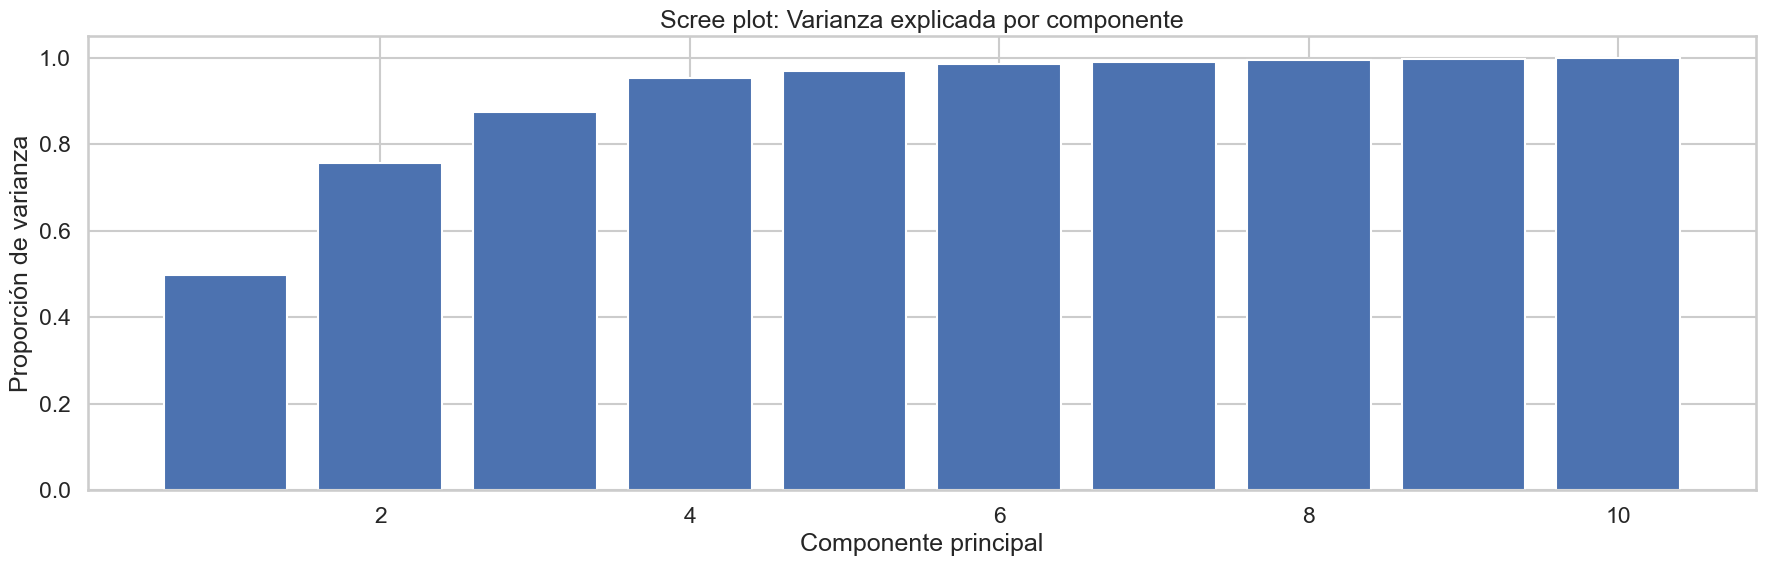

In [276]:
# Scree plot (una figura, sin estilos ni colores forzados)
plt.figure(figsize = (18, 6))
plt.bar(range(1, len(var_exp_acum)+1), var_exp_acum)
plt.title("Scree plot: Varianza explicada por componente")
plt.xlabel("Componente principal")
plt.ylabel("Proporción de varianza")
plt.tight_layout()
plt.show()


Varianza explicada con 2 PCs: 0.756
Varianza explicada con 3 PCs: 0.874


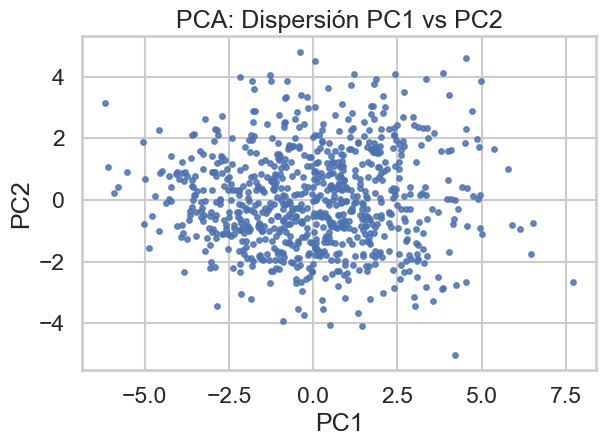

In [278]:
# -------------------------------
pca_2 = PCA(n_components=2)
X_pca2 = pca_2.fit_transform(X_std)

pca_3 = PCA(n_components=3)
X_pca3 = pca_3.fit_transform(X_std)

print("\nVarianza explicada con 2 PCs:", round(pca_2.explained_variance_ratio_.sum(), 3))
print("Varianza explicada con 3 PCs:", round(pca_3.explained_variance_ratio_.sum(), 3))

# Dispersión PC1 vs PC2
plt.figure()
plt.scatter(X_pca2[:, 0], X_pca2[:, 1], s=12, alpha=0.8)
plt.title("PCA: Dispersión PC1 vs PC2")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

Cargas 

In [282]:
loadings = pd.DataFrame(
    pca_2.components_.T,
    index=features,
    columns=["PC1", "PC2"]
).sort_values("PC1", ascending=False)

print("\nCargas para PC1 y PC2:")
display(loadings.round(3))


Cargas para PC1 y PC2:


,PC1,PC2
sesiones_mobile,0.425,-0.118
visitas,0.417,-0.192
paginas_vistas,0.416,-0.192
tiempo_sitio_min,0.412,-0.189
add_to_cart,0.275,0.464
compras,0.245,0.469
ticket_promedio,0.149,0.568
ratio_add_cart,0.114,0.282
devoluciones,-0.052,0.062
tasa_rebote,-0.360,0.189


### Pruebas de independencia con Survived

In [86]:
from scipy.stats import chi2_contingency
import numpy as np

In [87]:
def pruebaChi2(var):
    target = "Survived"
    data2 = data[[var, target]].dropna()
    tabla = pd.crosstab(data2[var], data2[target])
    chi2, p, dof, expected = chi2_contingency(tabla)
    return chi2, p

In [88]:
pruebaChi2("Sex")

(260.71702016732104, 1.197357062775565e-58)

In [89]:
pruebaChi2("Pclass")

(102.88898875696056, 4.549251711298793e-23)

In [90]:
pruebaChi2("SibSp")

(37.2717929152043, 1.5585810465902147e-06)

In [91]:
pruebaChi2("Parch")

(27.925784060236168, 9.703526421039997e-05)

## Imputación de datos

In [93]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [94]:
data[data["Age"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...,...
859,860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
868,869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S
878,879,0,3,"Laleff, Mr. Kristo",male,NaN,0,0,349217,7.8958,NaN,S


In [95]:
data[data["Embarked"].isna()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


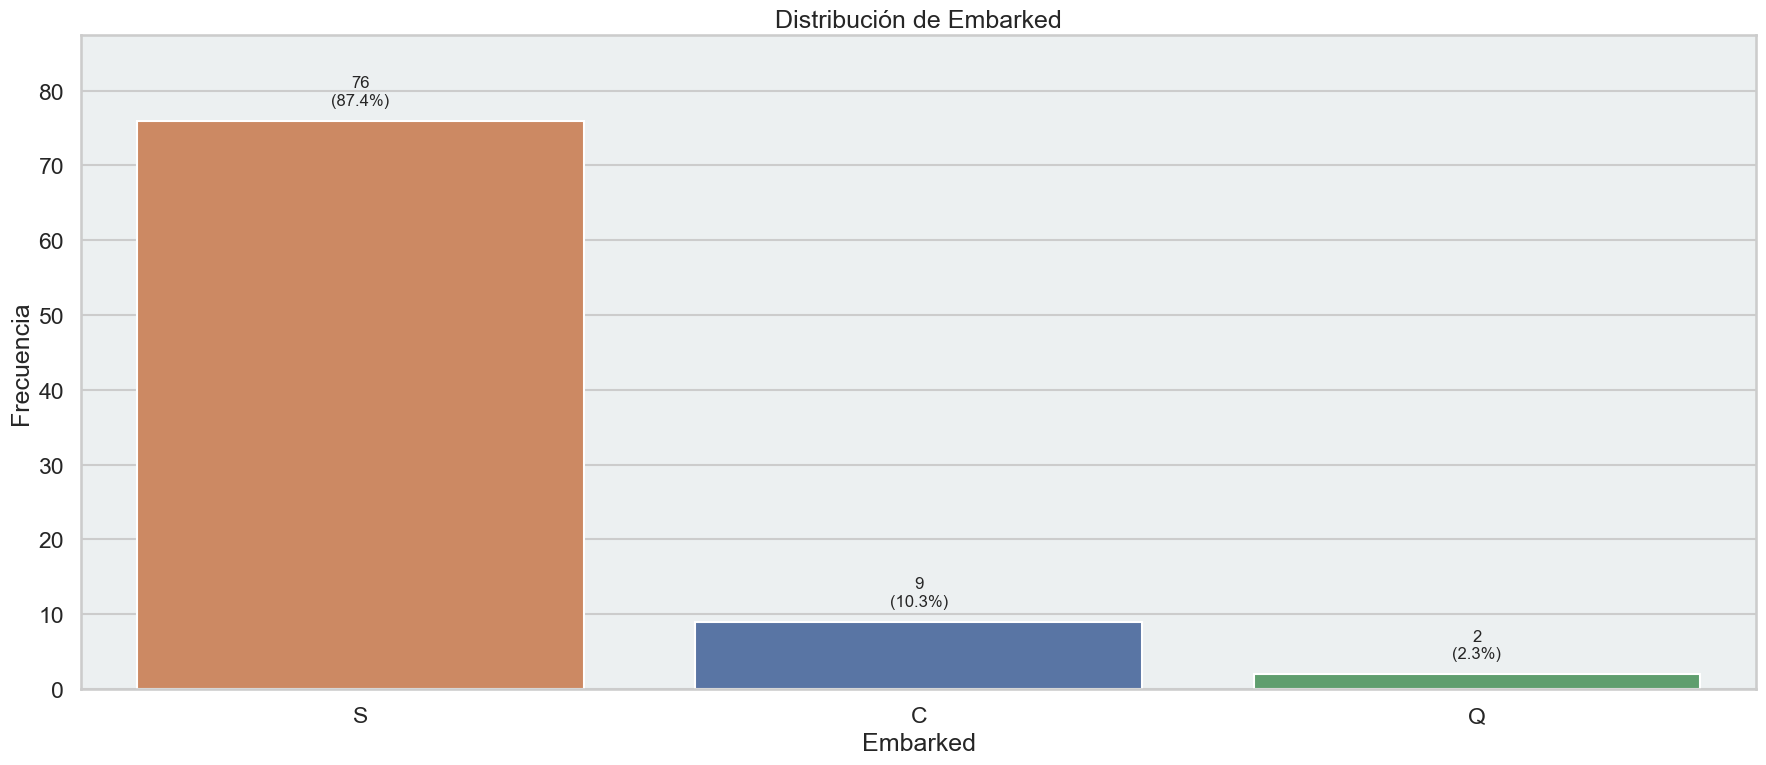

In [96]:
data2 = data[data["Survived"] == 1]
GraficoCategorias("Embarked", "deep", data = data2[data2["Pclass"] == 2])

In [97]:
data[data["Ticket"] == "113572"]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


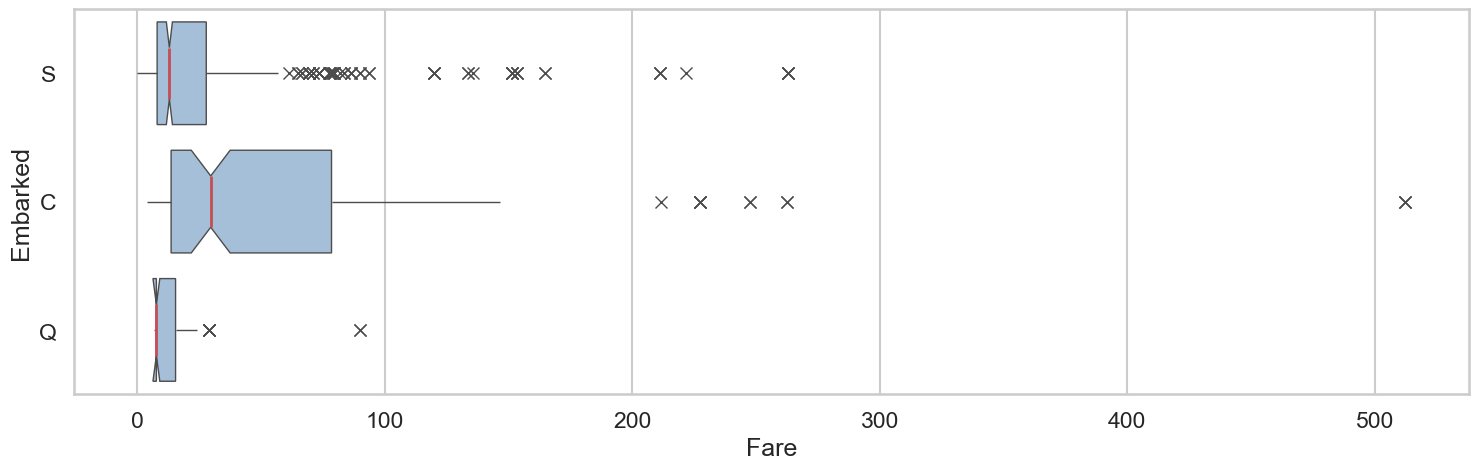

In [98]:
GraficaBoxPlot2(data, x = "Fare", y = "Embarked")